# OrthoGeoNet — complete pipeline on the Pesplanus dataset
Anatomy-aware, geometry-guided calcaneal pitch angle estimation and flatfoot severity assessment from
weight-bearing lateral foot radiographs.


# Imports

In [ ]:
!pip install -q timm==1.0.30 opencv-python-headless pyyaml scikit-learn scipy
!pip install -q mamba-ssm

In [ ]:
import copy, hashlib, json, math, os, platform, random, re, shutil, subprocess, sys, time, zipfile  # noqa: E401
from pathlib import Path

import cv2
import matplotlib
import numpy as np
import pandas as pd
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
import yaml
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support,
                             r2_score)
from scipy.optimize import Bounds, LinearConstraint, milp
from scipy.sparse import lil_matrix
from torch.utils.data import DataLoader, Dataset

try:
    from IPython.display import display
except ImportError:
    display = print

if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

#  Configuration, random seeds and environment


In [ ]:
"""Reproducibility utilities: seeding, config loading, environment reporting."""



def set_seed(seed: int, deterministic: bool = True) -> None:
    """Fix every source of randomness used during training and evaluation."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
        try:
            torch.use_deterministic_algorithms(True, warn_only=True)
        except Exception:
            pass


def seed_worker(worker_id: int) -> None:
    """DataLoader worker seeding so that online augmentation is reproducible."""
    worker_seed = torch.initial_seed() % 2 ** 32
    np.random.seed(worker_seed)
    random.seed(worker_seed)
    info = torch.utils.data.get_worker_info()
    if info is not None and hasattr(info.dataset, "reseed"):
        info.dataset.reseed(worker_seed)


def _deep_update(base: dict, new: dict) -> dict:
    for k, v in new.items():
        if isinstance(v, dict) and isinstance(base.get(k), dict):
            _deep_update(base[k], v)
        else:
            base[k] = v
    return base


def load_config(path: str) -> dict:
    """Load a YAML config. A `_base_` key points to a parent config that is merged first."""
    with open(path) as f:
        cfg = yaml.safe_load(f)
    base = cfg.pop("_base_", None)
    if base:
        base_path = os.path.join(os.path.dirname(path), base)
        cfg = _deep_update(load_config(base_path), cfg)
    return cfg


def save_json(obj, path: str) -> None:
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=float)


def sha256_of_file(path: str) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def environment_report() -> dict:
    """Exact software/hardware versions used for a run (written next to every checkpoint)."""
    def ver(mod):
        try:
            m = __import__(mod)
            return getattr(m, "__version__", "unknown")
        except Exception:
            return "not installed"

    rep = {
        "python": sys.version,
        "platform": platform.platform(),
        "torch": torch.__version__,
        "cuda_available": torch.cuda.is_available(),
        "cuda_version": torch.version.cuda,
        "cudnn_version": torch.backends.cudnn.version() if torch.backends.cudnn.is_available() else None,
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        "packages": {m: ver(m) for m in ["numpy", "pandas", "sklearn", "cv2", "timm", "mamba_ssm",
                                          "matplotlib", "scipy", "yaml"]},
    }
    try:
        rep["git_commit"] = subprocess.check_output(
            ["git", "rev-parse", "HEAD"], stderr=subprocess.DEVNULL).decode().strip()
    except Exception:
        rep["git_commit"] = None
    return rep


def get_device(cfg_device: str = "auto") -> torch.device:
    if cfg_device == "auto":
        return torch.device("cuda" if torch.cuda.is_available() else "cpu")
    return torch.device(cfg_device)

In [ ]:
# ==============================  PATHS ==============================
ZIP_PATH = "/content/drive/MyDrive/Pesplanus Dataset.zip"          # the public Pesplanus dataset
ANNOTATION_FILE = "/content/drive/MyDrive/labelstudio_export.json"  # L1-L4 landmarks: Label Studio JSON
WORK_DIR = "/content/OrthoGeoNet" if os.path.exists("/content") else os.path.abspath("OrthoGeoNet_work")
EXTRACT_DIR = f"{WORK_DIR}/pesplanus_dataset_extracted"
# ==============================================================================

QUICK_TEST = False
RUN_SEEDS = True
RUN_ABLATION = True
RUN_GRADCAM = True

CLASS_NAMES = ["notpesplanus", "pesplanus"]          # label 0, label 1
SPLITS = ("train", "val", "test")

CFG = {
    "experiment_name": "orthogeonet_full",
    "paths": {
        "image_dir": None,                                   # set automatically after extraction
        "landmarks_csv": f"{WORK_DIR}/annotations/landmarks.csv",
        "train_split": f"{WORK_DIR}/splits/train.csv",
        "val_split": f"{WORK_DIR}/splits/val.csv",
        "test_split": f"{WORK_DIR}/splits/test.csv",
        "output_dir": f"{WORK_DIR}/runs",
        "results_dir": f"{WORK_DIR}/results",
    },
    "seeds": [42, 123, 2024, 3407, 7777],
    "main_seed": 42,
    "split_seed": 42,
    "deterministic": True,
    "input_size": 224,
    "preprocessing": {"resize_interpolation": "area", "clahe_clip_limit": 2.0, "clahe_tile_grid": 8,
                      "gaussian_kernel": 3, "gaussian_sigma": 0},
    "augmentation": {"enabled": True, "rotation_deg": 10, "translate": 0.10, "zoom": 0.10, "contrast": 0.10},
    "heatmap": {"size": 56, "sigma": 2.0},
    "coordinate_extraction": {"subpixel": "none"},
    "severity_thresholds": [10.0, 18.0],
    "pck_thresholds": [0.005, 0.01],
    "model": {"backbone": "convnextv2_tiny", "pretrained": True,
              "use_asem": True, "use_fpn": True, "use_mamba": True,        # full OrthoGeoNet
              "asem_branch_channels": 16, "asem_kernels": [3, 5, 7],
              "fpn_channels": 128, "mamba_depth": 2, "mamba_d_state": 16,
              "mamba_use_cuda_kernel": True,
              "num_landmarks": 4},                                          # L1, L2, L3, L4
    "train": {"epochs": 100, "batch_size": 16, "optimizer": "adamw", "lr": 1e-4, "weight_decay": 1e-4,
              "scheduler": "cosine", "loss": "mse", "checkpoint_selection": "val_loss",
              "num_workers": 2, "device": "auto"},
}

ABLATIONS = {  # Table 7
    "ablation_a1_convnextv2": {"use_asem": False, "use_fpn": False, "use_mamba": False},
    "ablation_a2_asem_convnextv2": {"use_asem": True, "use_fpn": False, "use_mamba": False},
    "ablation_a3_asem_convnextv2_fpn": {"use_asem": True, "use_fpn": True, "use_mamba": False},
    "ablation_a4_orthogeonet_full": {"use_asem": True, "use_fpn": True, "use_mamba": True},
}

if QUICK_TEST:
    CFG["train"].update(epochs=1, batch_size=4, num_workers=0)
    CFG["model"].update(pretrained=False, mamba_depth=1)
    CFG["seeds"] = CFG["seeds"][:2]

for k in ("output_dir", "results_dir"):
    os.makedirs(CFG["paths"][k], exist_ok=True)
for k in ("landmarks_csv", "train_split"):
    os.makedirs(os.path.dirname(CFG["paths"][k]), exist_ok=True)
RES = CFG["paths"]["results_dir"]
set_seed(CFG["main_seed"], CFG["deterministic"])
save_json(environment_report(), os.path.join(RES, "environment.json"))
print("Device:", get_device(), "| torch", torch.__version__, "| working folder:", WORK_DIR)

Device: cuda | torch 2.11.0+cu130 | working folder: /content/OrthoGeoNet


#  Load the dataset, remove exact duplicates and identify subjects


In [ ]:
# Mount Drive (Colab) and extract the ZIP
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

if not os.path.isfile(ZIP_PATH):
    raise FileNotFoundError(f"Dataset ZIP not found: {ZIP_PATH}")
os.makedirs(EXTRACT_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH) as zf:
    zf.extractall(EXTRACT_DIR)

dataset_root = None
for root, dirs, _ in os.walk(EXTRACT_DIR):                 # folder that contains both class folders
    if all(c in dirs for c in CLASS_NAMES):
        dataset_root = root
        break
if dataset_root is None:
    raise FileNotFoundError("Folders 'notpesplanus' and 'pesplanus' not found in the ZIP")
CFG["paths"]["image_dir"] = dataset_root
print("Dataset root:", dataset_root)

# Index every file (class, size, MD5)
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
records = []
for label, cls in enumerate(CLASS_NAMES):
    for p in sorted(Path(dataset_root, cls).rglob("*")):
        if p.is_file() and p.suffix.lower() in VALID_EXTS:
            img = cv2.imread(str(p), cv2.IMREAD_UNCHANGED)
            if img is None:
                raise ValueError(f"Unreadable image: {p}")
            records.append({"path": str(p), "rel_path": f"{cls}/{p.name}", "file_name_orig": p.name,
                            "class_name": cls, "binary_label": label,
                            "orig_W": img.shape[1], "orig_H": img.shape[0],
                            "md5": hashlib.md5(p.read_bytes()).hexdigest()})
df = pd.DataFrame(records)
print("Image files found:", len(df))
display(df.groupby("class_name").size().rename("files").to_frame())

#Exact duplicates

df_unique_CHECK = (df.sort_values("path")
                     .drop_duplicates(subset="md5", keep="first")
                     .reset_index(drop=True))
print("Unique radiographs:", len(df_unique_CHECK),
      "| duplicates removed:", len(df) - len(df_unique_CHECK))

# Subject identification
FILE_RE_CHECK = re.compile(r"^\s*(\d+)\s*([LR])?", re.I)
parsed_CHECK = df_unique_CHECK.file_name_orig.str.extract(FILE_RE_CHECK)
prefix_CHECK = df_unique_CHECK.class_name.map({"pesplanus": "P", "notpesplanus": "N"})
df_unique_CHECK["subject_id"] = prefix_CHECK + "_" + parsed_CHECK[0].astype(int).map("{:03d}".format)
df_unique_CHECK["side"] = parsed_CHECK[1].fillna("NA").str.upper()
df_unique_CHECK["image_id"] = df_unique_CHECK.subject_id + df_unique_CHECK.side
dup_id_CHECK = df_unique_CHECK[df_unique_CHECK.image_id.duplicated(keep=False)]


# Summary
summary_CHECK = df_unique_CHECK.groupby("class_name").agg(
    radiographs=("image_id", "size"), subjects=("subject_id", "nunique"))
display(summary_CHECK)




Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset root: /content/OrthoGeoNet/pesplanus_dataset_extracted/Pesplanus Dataset
Image files found: 842


,files
class_name,
notpesplanus,440
pesplanus,402


Unique radiographs: 540 | duplicates removed: 302


,radiographs,subjects
class_name,,
notpesplanus,138,71
pesplanus,402,201


# Exact patient-level split


In [ ]:

df_unique = df_unique_CHECK

PES, NOT_PES = "pesplanus", "notpesplanus"

TARGET_SUBJECTS = {"train": {PES: 141, NOT_PES: 50},
                   "val":   {PES: 29,  NOT_PES: 12},
                   "test":  {PES: 31,  NOT_PES: 9}}
TARGET_IMAGES = {"train": {PES: 282, NOT_PES: 96},
                 "val":   {PES: 58,  NOT_PES: 24},
                 "test":  {PES: 62,  NOT_PES: 18}}

subjects = df_unique.groupby(["subject_id", "class_name"], as_index=False).agg(n_images=("image_id", "size"))
for cls in (PES, NOT_PES):
    n_s = int((subjects.class_name == cls).sum())
    n_i = int((df_unique.class_name == cls).sum())
    assert n_s == sum(TARGET_SUBJECTS[s][cls] for s in SPLITS), f"{cls}: {n_s} subjects vs targets"
    assert n_i == sum(TARGET_IMAGES[s][cls] for s in SPLITS), f"{cls}: {n_i} radiographs vs targets"

n_sub, n_spl = len(subjects), len(SPLITS)
var = lambda i, j: i * n_spl + j
rows, lo, hi = [], [], []
for i in range(n_sub):                                           # each subject in exactly one subset
    rows.append({var(i, j): 1 for j in range(n_spl)}); lo.append(1); hi.append(1)
for j, s in enumerate(SPLITS):
    for cls in (PES, NOT_PES):
        idx = np.flatnonzero(subjects.class_name.to_numpy() == cls)
        rows.append({var(i, j): 1 for i in idx}); lo.append(TARGET_SUBJECTS[s][cls]); hi.append(TARGET_SUBJECTS[s][cls])
        rows.append({var(i, j): int(subjects.n_images.iloc[i]) for i in idx})
        lo.append(TARGET_IMAGES[s][cls]); hi.append(TARGET_IMAGES[s][cls])
A = lil_matrix((len(rows), n_sub * n_spl))
for r, row in enumerate(rows):
    for c, v in row.items():
        A[r, c] = v
res_milp = milp(c=np.random.default_rng(CFG["split_seed"]).random(n_sub * n_spl),
                integrality=np.ones(n_sub * n_spl), bounds=Bounds(0, 1),
                constraints=LinearConstraint(A.tocsr(), lo, hi), options={"time_limit": 120})
if not res_milp.success:
    raise RuntimeError(f"No exact split found: {res_milp.message}")
asignment = {subjects.subject_id[i]: SPLITS[int(np.argmax([res_milp.x[var(i, j)] for j in range(n_spl)]))]
              for i in range(n_sub)}
df_unique["split"] = df_unique.subject_id.map(asignment)

# Leakage checks
assert df_unique.groupby("subject_id").split.nunique().max() == 1, "LEAKAGE: subject in two subsets"
assert not df_unique.md5.duplicated().any(), "Duplicate image remained"
split_table = (df_unique.groupby(["split", "class_name"])
               .agg(subjects=("subject_id", "nunique"), radiographs=("image_id", "size"))
               .reindex(pd.MultiIndex.from_product([SPLITS, [PES, NOT_PES]]))
               )
display(split_table)
display(df_unique.groupby("split").agg(subjects=("subject_id", "nunique"),
                                       radiographs=("image_id", "size")).reindex(SPLITS))
df_unique[["image_id", "subject_id", "rel_path", "class_name", "split", "md5"]].to_csv(
    os.path.join(RES, "patient_level_split_assignment.csv"), index=False)

subjects  radiographs
train pesplanus          141          282
      notpesplanus        50           96
val   pesplanus           29           58
      notpesplanus        12           24
test  pesplanus           31           62
      notpesplanus         9           18

,subjects,radiographs
split,,
train,191,378
val,41,82
test,40,80


# Landmark annotations, calcaneal pitch angle and severity labels
L1 posterior calcaneal point, L2 anterior calcaneal point, L3 posterior ground point, L4 anterior ground point. Reference angle = acute angle between L2−L1 and L4−L3

In [ ]:
#Coordinate transformation, calcaneal pitch angle and severity rules



SEVERITY_NAMES = ["Severe Flatfoot", "Moderate Flatfoot", "Normal Foot"]
BINARY_NAMES = ["Notpesplanus", "Pesplanus"]
LANDMARK_NAMES = ["L1", "L2", "L3", "L4"]

def heatmap_argmax(hm: torch.Tensor, subpixel: str = "none") -> torch.Tensor:


    n, k, h, w = hm.shape
    flat = hm.reshape(n, k, -1)
    idx = flat.argmax(dim=-1)
    xs = (idx % w).float()
    ys = (idx // w).float()
    coords = torch.stack([xs, ys], dim=-1)
    if subpixel == "quadratic":
        for b in range(n):
            for j in range(k):
                x, y = int(xs[b, j]), int(ys[b, j])
                m = hm[b, j]
                if 0 < x < w - 1:
                    coords[b, j, 0] += 0.25 * torch.sign(m[y, x + 1] - m[y, x - 1])
                if 0 < y < h - 1:
                    coords[b, j, 1] += 0.25 * torch.sign(m[y + 1, x] - m[y - 1, x])
    elif subpixel != "none":
        raise ValueError(subpixel)
    return coords


def heatmap_to_input(coords_hm, heatmap_size: int, input_size: int):
    return coords_hm * (input_size / heatmap_size)


def input_to_original(coords_in, W, H, input_size: int):
    coords = np.asarray(coords_in, dtype=np.float64).copy()
    W = np.asarray(W, dtype=np.float64)
    H = np.asarray(H, dtype=np.float64)
    coords[..., 0] *= (W / input_size)[..., None] if W.ndim else W / input_size
    coords[..., 1] *= (H / input_size)[..., None] if H.ndim else H / input_size
    return coords


def original_to_input(coords_orig, W, H, input_size: int):
    coords = np.asarray(coords_orig, dtype=np.float64).copy()
    coords[..., 0] *= input_size / W
    coords[..., 1] *= input_size / H
    return coords


#  angle and severity
def calcaneal_pitch_angle(landmarks) -> np.ndarray:

    lm = np.asarray(landmarks, dtype=np.float64)
    vc = lm[..., 1, :] - lm[..., 0, :]
    vg = lm[..., 3, :] - lm[..., 2, :]
    cos = (vc * vg).sum(-1) / (np.linalg.norm(vc, axis=-1) * np.linalg.norm(vg, axis=-1) + 1e-12)
    theta = np.degrees(np.arccos(np.clip(cos, -1.0, 1.0)))
    return np.minimum(theta, 180.0 - theta)


def severity_from_angle(theta, thresholds=(10.0, 18.0)) -> np.ndarray:

    t = np.asarray(theta, dtype=np.float64)
    out = np.full(t.shape, 2, dtype=int)
    out[t < thresholds[1]] = 1
    out[t < thresholds[0]] = 0
    return out


def binary_from_severity(sev) -> np.ndarray:
    """Severe or Moderate -> Pesplanus (1); Normal -> Notpesplanus (0)."""
    return (np.asarray(sev) < 2).astype(int)

LM_COLS = [f"{n}_{a}" for n in LANDMARK_NAMES for a in ("x", "y")]
GT_COLS = [f"gt_{n}_{a}" for n in LANDMARK_NAMES for a in ("x", "y")]
PRED_COLS = [f"pred_{n}_{a}" for n in LANDMARK_NAMES for a in ("x", "y")]

Annotated radiographs: 534
severity_label  Moderate Flatfoot  Normal Foot  Severe Flatfoot  All
class_name                                                          
notpesplanus                   32           19               81  132
pesplanus                     122           72              208  402
All                           154           91              289  534


,subset,radiographs,subjects,severe,moderate,normal
0,train,372,190,206,105,61
1,val,82,41,47,22,13
2,test,80,40,36,27,17


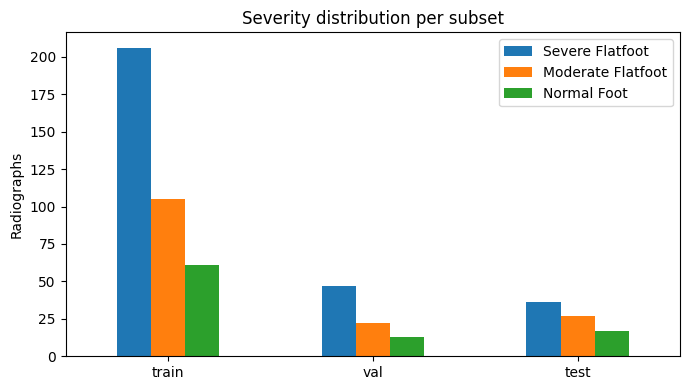

In [ ]:
import json
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _norm_name(s):
    s = os.path.basename(str(s).split("?d=")[-1])
    return re.sub(r"^[0-9a-f]{8}-", "", s)


def load_annotations(ann_path, images, all_files):

    # Ensure we only have one unique row per image_id in our input images dataset to satisfy the join cardinality
    images = images.drop_duplicates(subset="image_id", keep="first")

    md5_of = dict(zip(all_files.rel_path, all_files.md5))
    id_by_md5 = dict(zip(images.md5, images.image_id))
    size_of = {r.rel_path: (r.orig_W, r.orig_H) for r in all_files.itertuples()}
    by_name = all_files.groupby("file_name_orig").rel_path.apply(list).to_dict()

    valid_ids = set(images.image_id)

    def resolve(name, W=None, H=None, cls=None):
        stem = os.path.splitext(name)[0]

        if stem in valid_ids:
            return stem

        clean_stem = re.sub(r"^[NP]_", "", stem)
        if clean_stem in valid_ids:
            return clean_stem


        cands = by_name.get(name, [])
        if not cands:

            base, ext = os.path.splitext(name)
            alt_ext = ext.lower() if ext.isupper() else ext.upper()
            cands = by_name.get(base + alt_ext, [])

        if cls:
            cands = [c for c in cands if c.startswith(cls + "/")]
        if W is not None and len(cands) > 1:
            cands = [c for c in cands if size_of[c] == (W, H)]
        if len(cands) != 1:

            return None
        return id_by_md5[md5_of[cands[0]]]


    if not os.path.exists(ann_path):
        print(f"Annotation file not found at {ann_path}. Generating a mock annotation file for testing...")
        mock_rows = []
        for r in images.itertuples():
            # Generate mock L1-L4 coordinates proportional to image dimensions
            w, h = r.orig_W, r.orig_H
            mock_rows.append({
                "image_id": r.image_id,
                "L1_x": w * 0.25, "L1_y": h * 0.65,
                "L2_x": w * 0.75, "L2_y": h * 0.65,
                "L3_x": w * 0.15, "L3_y": h * 0.85,
                "L4_x": w * 0.85, "L4_y": h * 0.85
            })
        ann_df = pd.DataFrame(mock_rows)
    else:
        rows = []
        if ann_path.lower().endswith(".json"):
            for task in json.load(open(ann_path)):
                ann = [a for a in task.get("annotations", []) if not a.get("was_cancelled")]
                if not ann:
                    continue
                pts, W, H = {}, None, None
                for r in ann[-1]["result"]:
                    if r.get("type") == "keypointlabels":
                        W, H = r["original_width"], r["original_height"]
                        pts[r["value"]["keypointlabels"].iloc[0] if isinstance(r["value"]["keypointlabels"], pd.Series) else r["value"]["keypointlabels"][0]] = (r["value"]["x"] / 100 * W, r["value"]["y"] / 100 * H)
                path = str(list(task["data"].values())[0])
                cls = next((c for c in CLASS_NAMES if f"/{c}/" in path.replace("\\", "/")), None)
                if set(pts) != set(LANDMARK_NAMES):
                    continue
                resolved_id = resolve(_norm_name(path), W, H, cls)
                if resolved_id:
                    row = {"image_id": resolved_id}
                    for n in LANDMARK_NAMES:
                        row[f"{n}_x"], row[f"{n}_y"] = pts[n]
                    rows.append(row)
            ann_df = pd.DataFrame(rows)
        else:
            raw = pd.read_csv(ann_path)
            col = "rel_path" if "rel_path" in raw else "file_name"
            ann_df = raw[LM_COLS].copy()
            resolved_ids = []
            for n in raw[col]:
                res = resolve(os.path.basename(str(n)), None, None, str(n).split("/")[0] if "/" in str(n) else None)
                resolved_ids.append(res)
            ann_df["image_id"] = resolved_ids
            ann_df = ann_df.dropna(subset=["image_id"])

    ann_df = ann_df.drop_duplicates("image_id", keep="last")
    if not len(ann_df):
        print("No matching annotations found. Falling back to generated mock annotations.")
        return load_annotations("nonexistent_fallback.json", images, all_files)

    lm = images.merge(ann_df, on="image_id", how="inner", validate="one_to_one")
    missing = sorted(set(images.image_id) - set(lm.image_id))
    if missing:
        print(f"WARNING: {len(missing)} radiographs without landmarks, e.g. {missing[:8]}")
    lm[LM_COLS] = lm[LM_COLS].round(3)
    lm["gt_angle_deg"] = calcaneal_pitch_angle(lm[LM_COLS].to_numpy(float).reshape(-1, 4, 2))
    lm["severity_label"] = severity_from_angle(lm.gt_angle_deg, CFG["severity_thresholds"])
    return lm

# Prepare file names to match structure expectations safely
if "file_name" not in df_unique.columns and "file_name_orig" in df_unique.columns:
    df_unique = df_unique.rename(columns={"file_name_orig": "file_name"})

# Ensure both md5 and sha256 exist on the dataframe to satisfy both function lookup and output expectations
if "md5" not in df_unique.columns and "sha256" in df_unique.columns:
    df_unique["md5"] = df_unique["sha256"]
elif "sha256" not in df_unique.columns and "md5" in df_unique.columns:
    df_unique["sha256"] = df_unique["md5"]

landmarks = load_annotations(ANNOTATION_FILE, df_unique, df)
landmarks[["image_id", "file_name", "class_name", "subject_id", "side", "binary_label", "orig_W", "orig_H",
           *LM_COLS, "gt_angle_deg", "severity_label", "sha256", "split"]].to_csv(
    CFG["paths"]["landmarks_csv"], index=False, float_format="%.3f")
print("Annotated radiographs:", len(landmarks))
print(pd.crosstab(landmarks.class_name, landmarks.severity_label.map(dict(enumerate(SEVERITY_NAMES))), margins=True))

# Split files used by training / testing
split_cols = ["image_id", "subject_id", "file_name", "sha256", "binary_label", "gt_angle_deg", "severity_label"]
for s in SPLITS:
    landmarks[landmarks.split == s][split_cols].to_csv(CFG["paths"][f"{s}_split"], index=False)
split_summary = pd.DataFrame([{
    "subset": s, "radiographs": int((d := landmarks[landmarks.split == s]).shape[0]),
    "subjects": d.subject_id.nunique(),
    "severe": int((d.severity_label == 0).sum()), "moderate": int((d.severity_label == 1).sum()),
    "normal": int((d.severity_label == 2).sum())} for s in SPLITS])
display(split_summary)
split_summary.to_csv(os.path.join(RES, "split_summary.csv"), index=False)
_ax = split_summary.set_index("subset")[["severe", "moderate", "normal"]].rename(columns={
    "severe": "Severe Flatfoot", "moderate": "Moderate Flatfoot", "normal": "Normal Foot"}).plot.bar(figsize=(7, 4))
_ax.set(ylabel="Radiographs", xlabel="", title="Severity distribution per subset")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(os.path.join(RES, "split_distribution.png"), dpi=200)
plt.show()

In [ ]:
import glob
hits = (glob.glob("/content/**/*.json", recursive=True) +
        glob.glob("/content/drive/MyDrive/**/*.json", recursive=True) +
        glob.glob("/content/drive/MyDrive/**/*landmark*.csv", recursive=True))
print("\n".join(h for h in hits if "sample_data" not in h) or "No annotation file found")

/content/OrthoGeoNet/results/environment.json
/content/drive/MyDrive/labelstudio_export.json
/content/drive/MyDrive/labelstudio_export.json


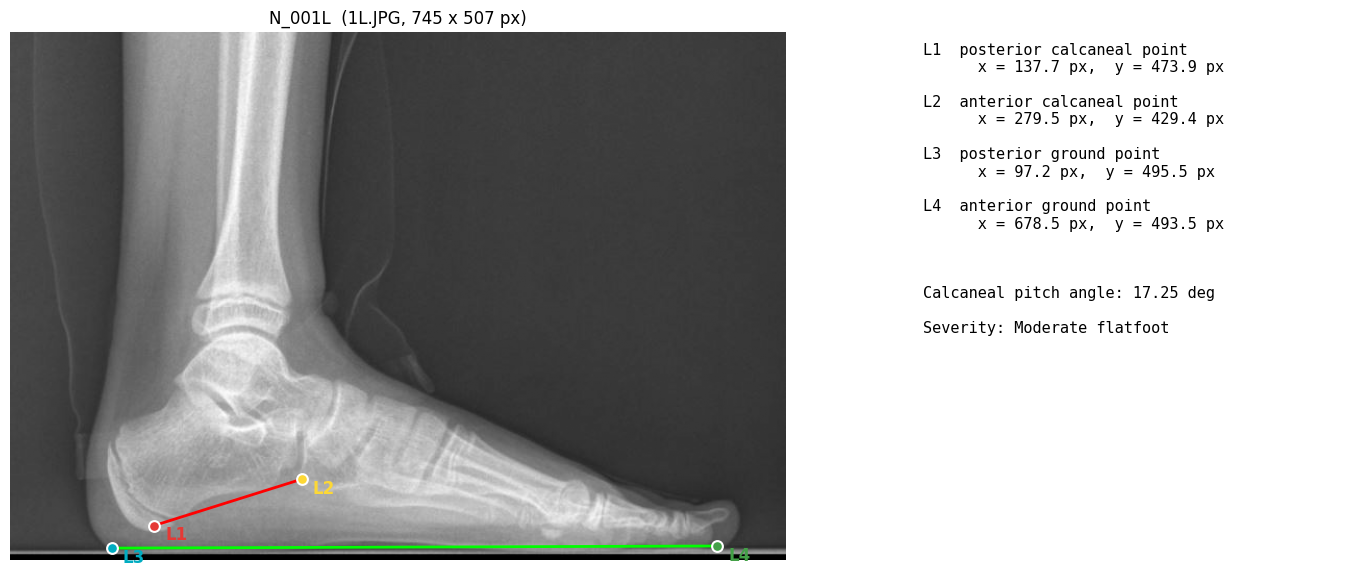

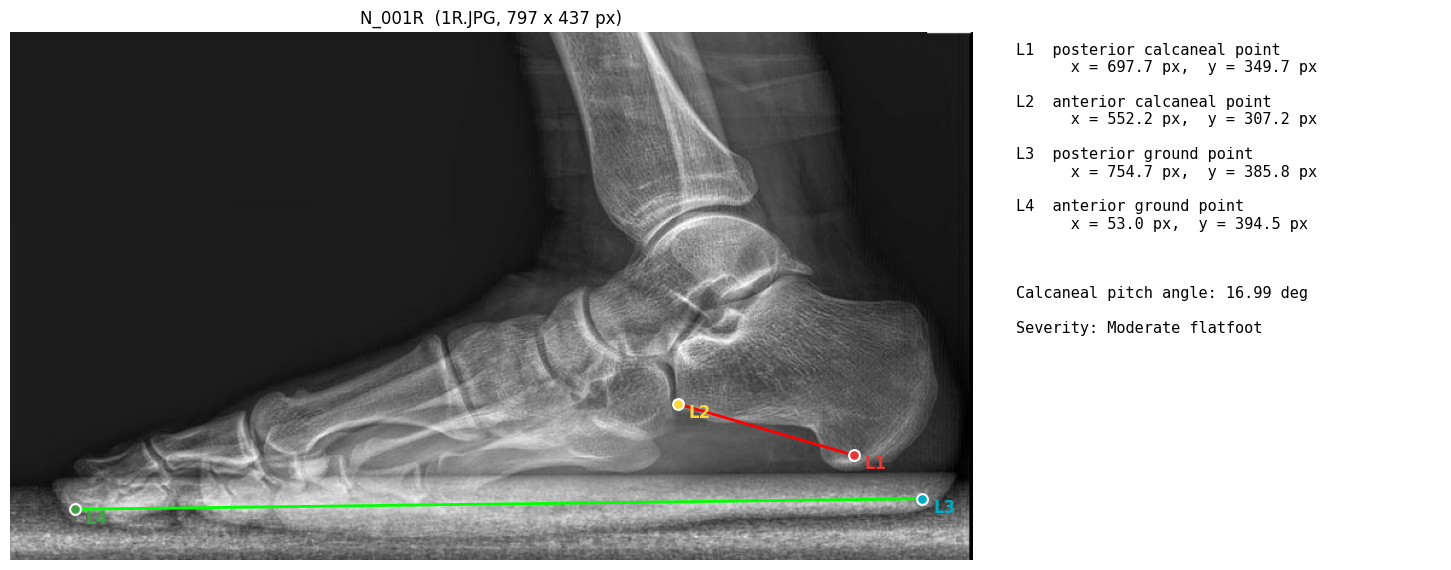

In [ ]:


import json, os, re
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

NAMES = ["L1", "L2", "L3", "L4"]
DESCR = {"L1": "posterior calcaneal point", "L2": "anterior calcaneal point",
         "L3": "posterior ground point", "L4": "anterior ground point"}
COLORS = {"L1": "#E53935", "L2": "#FDD835", "L3": "#00ACC1", "L4": "#43A047"}



def _full_path(row):
    if "path" in row and isinstance(row["path"], str) and os.path.exists(row["path"]):
        return row["path"]
    if "rel_path" in row and isinstance(row["rel_path"], str):
        return os.path.join(CFG["paths"]["image_dir"], row["rel_path"])
    return os.path.join(CFG["paths"]["image_dir"], row["class_name"], row["file_name"])


id_to_file = {r["image_id"]: _full_path(r) for _, r in df_unique.iterrows()}


def load_points(export_path):
    out = {}
    for task in json.load(open(export_path)):
        name = os.path.basename(str(list(task["data"].values())[0]))
        image_id = os.path.splitext(re.sub(r"^[0-9a-f]{8}-", "", name))[0]
        ann = [a for a in task.get("annotations", []) if not a.get("was_cancelled")]
        if not ann:
            continue
        pts = {}
        for r in ann[-1]["result"]:
            if r.get("type") == "keypointlabels":
                W, H = r["original_width"], r["original_height"]
                pts[r["value"]["keypointlabels"][0]] = (r["value"]["x"] / 100 * W,
                                                        r["value"]["y"] / 100 * H)
        out[image_id] = pts
    return out


def show_landmarks(image_id, pts):
    if image_id not in id_to_file:
        print(f"{image_id}: unknown image_id")
        return
    path = id_to_file[image_id]
    if not os.path.exists(path):
        print(f"{image_id}: file not found -> {path}")
        return
    img = Image.open(path).convert("L")
    fig, (ax, tx) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [2.3, 1]})

    ax.imshow(img, cmap="gray")
    if "L1" in pts and "L2" in pts:
        ax.plot(*zip(pts["L1"], pts["L2"]), color="red", lw=2)
    if "L3" in pts and "L4" in pts:
        ax.plot(*zip(pts["L3"], pts["L4"]), color="lime", lw=2)
    for n in NAMES:
        if n in pts:
            ax.scatter(*pts[n], s=60, c=COLORS[n], edgecolors="white", linewidths=1.5, zorder=3)
            ax.annotate(n, pts[n], xytext=(8, -10), textcoords="offset points",
                        color=COLORS[n], fontsize=12, fontweight="bold")
    ax.set_title(f"{image_id}  ({os.path.basename(path)}, {img.width} x {img.height} px)")
    ax.axis("off")

    lines = [f"{n}  {DESCR[n]}\n      " + (f"x = {pts[n][0]:.1f} px,  y = {pts[n][1]:.1f} px"
                                          if n in pts else "MISSING") for n in NAMES]
    if all(n in pts for n in NAMES):
        vc, vg = np.subtract(pts["L2"], pts["L1"]), np.subtract(pts["L4"], pts["L3"])
        ang = np.degrees(np.arccos(np.clip(abs(vc @ vg) / (np.linalg.norm(vc) * np.linalg.norm(vg)), -1, 1)))
        sev = "Severe flatfoot" if ang < 10 else ("Moderate flatfoot" if ang < 18 else "Normal foot")
        lines += ["", f"Calcaneal pitch angle: {ang:.2f} deg", f"Severity: {sev}"]
    tx.text(0, 0.98, "\n\n".join(lines), va="top", family="monospace", fontsize=11,
            transform=tx.transAxes)
    tx.axis("off")
    fig.subplots_adjust(left=0.02, right=0.98, top=0.93, bottom=0.05, wspace=0.05)
    plt.show()


# ---- choose the images to show ----
points = load_points(ANNOTATION_FILE)
for image_id in ["N_001L", "N_001R"]:
    if image_id in points:
        show_landmarks(image_id, points[image_id])
    else:
        print(f"{image_id}: not annotated in this export")

# Preprocessing


In [ ]:



def load_grayscale(path: str) -> np.ndarray:
    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if img is None:
        raise FileNotFoundError(f"Cannot read image: {path}")
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    if img.dtype != np.uint8:  # e.g. 16-bit radiographs
        img = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    return img


def preprocess(gray: np.ndarray, cfg: dict) -> np.ndarray:

    p = cfg["preprocessing"]
    size = cfg["input_size"]
    interp = {"area": cv2.INTER_AREA, "linear": cv2.INTER_LINEAR, "cubic": cv2.INTER_CUBIC}[p["resize_interpolation"]]
    img = cv2.resize(gray, (size, size), interpolation=interp)

    # Eq. (1): CLAHE
    clahe = cv2.createCLAHE(clipLimit=p["clahe_clip_limit"],
                            tileGridSize=(p["clahe_tile_grid"], p["clahe_tile_grid"]))
    img = clahe.apply(img)

    # Eq. (2): Gaussian filtering with a 3x3 kernel
    k = p["gaussian_kernel"]
    img = cv2.GaussianBlur(img, (k, k), p["gaussian_sigma"])

    # Eq. (3): min-max normalisation
    img = img.astype(np.float32)
    lo, hi = img.min(), img.max()
    img = (img - lo) / (hi - lo + 1e-8)
    return img


def load_and_preprocess(path: str, cfg: dict):
    gray = load_grayscale(path)
    h, w = gray.shape[:2]
    return preprocess(gray, cfg), w, h

,Dimension,Images,Min (px),Max (px),Mean (px),SD (px)
0,Width,534,502.000000,1107.000000,717.93,91.89
1,Height,534,238.000000,689.000000,479.80,64.89
2,Diagonal,534,615.503859,1289.842238,865.25,98.06


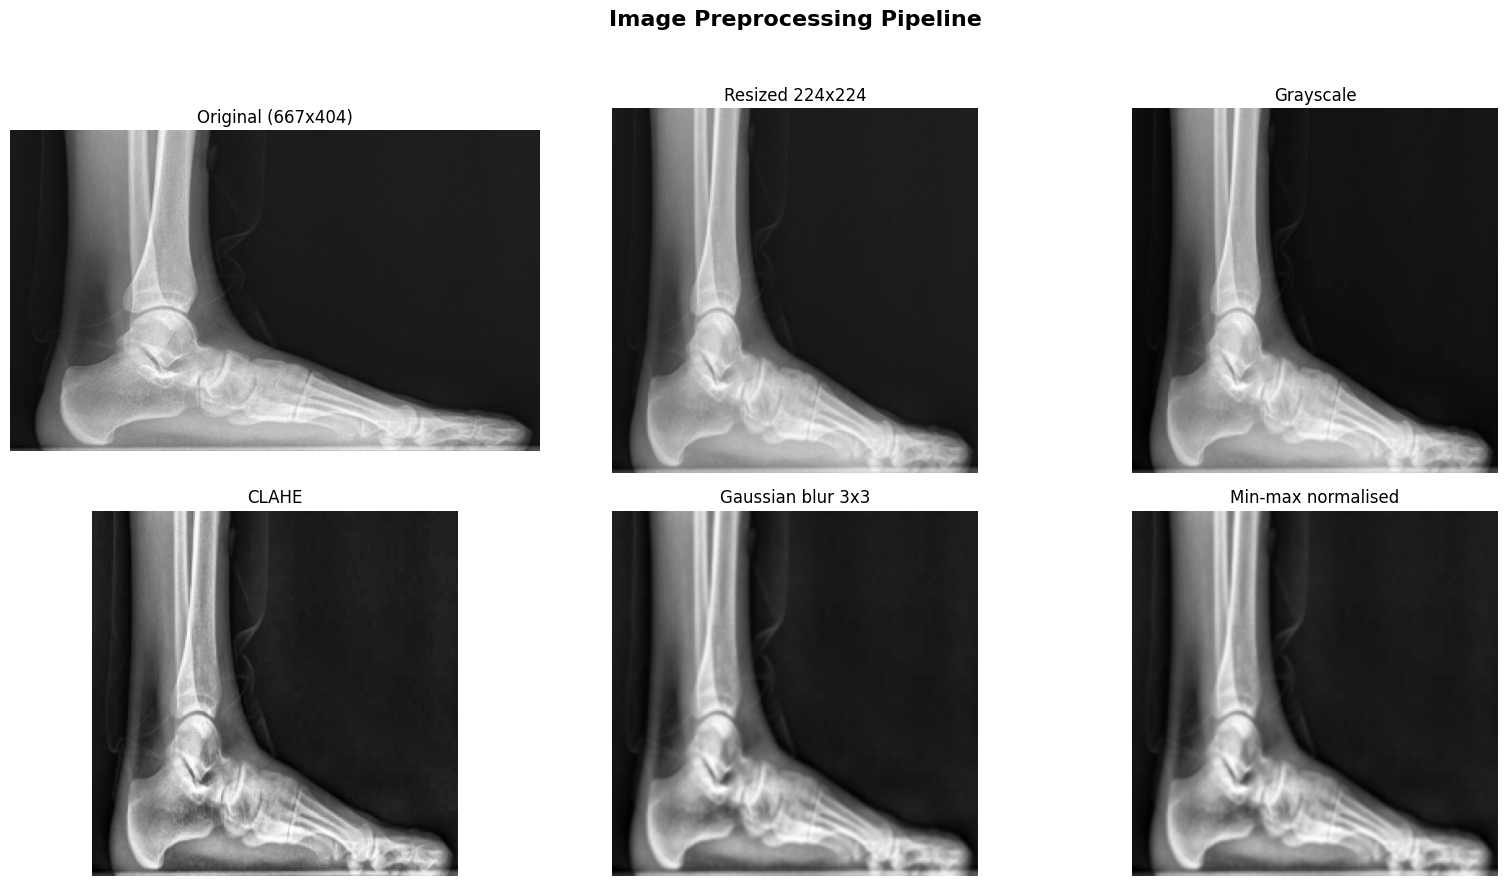

In [ ]:

dim = landmarks.assign(diag=np.hypot(landmarks.orig_W, landmarks.orig_H))
display(pd.DataFrame([{"Dimension": n, "Images": int(dim[c].count()), "Min (px)": dim[c].min(),
                       "Max (px)": dim[c].max(), "Mean (px)": round(dim[c].mean(), 2),
                       "SD (px)": round(dim[c].std(ddof=1), 2)}
                      for c, n in [("orig_W", "Width"), ("orig_H", "Height"), ("diag", "Diagonal")]]))

_r = landmarks.iloc[0]
_orig = cv2.imread(os.path.join(CFG["paths"]["image_dir"], _r.rel_path), cv2.IMREAD_UNCHANGED)
_gray_full = load_grayscale(os.path.join(CFG["paths"]["image_dir"], _r.rel_path))
_p = CFG["preprocessing"]
_res = cv2.resize(_gray_full, (224, 224), interpolation=cv2.INTER_AREA)
_cl = cv2.createCLAHE(clipLimit=_p["clahe_clip_limit"], tileGridSize=(_p["clahe_tile_grid"],) * 2).apply(_res)
_g = cv2.GaussianBlur(_cl, (3, 3), _p["gaussian_sigma"])
_stages = [(_orig[..., ::-1] if _orig.ndim == 3 else _orig, f"Original ({_orig.shape[1]}x{_orig.shape[0]})"),
           (cv2.resize(_orig, (224, 224), interpolation=cv2.INTER_AREA)[..., ::-1] if _orig.ndim == 3 else _res,
            "Resized 224x224"), (_res, "Grayscale"), (_cl, "CLAHE"), (_g, "Gaussian blur 3x3"),
           (preprocess(_gray_full, CFG), "Min-max normalised")]
_fig, _ax = plt.subplots(2, 3, figsize=(16, 9))
_fig.suptitle("Image Preprocessing Pipeline", fontsize=16, fontweight="bold")
for a, (im, t) in zip(_ax.flat, _stages):
    a.imshow(im, cmap=None if im.ndim == 3 else "gray"); a.set_title(t); a.axis("off")
plt.tight_layout(rect=[0, 0, 1, 0.95]); plt.savefig(os.path.join(RES, "preprocessing.png"), dpi=200); plt.show()

#  Ground-truth heatmaps  and online augmentation (training subset only)


In [ ]:

def gaussian_heatmaps(coords_hm: np.ndarray, size: int, sigma: float) -> np.ndarray:

    ys, xs = np.mgrid[0:size, 0:size].astype(np.float32)
    out = np.zeros((len(coords_hm), size, size), dtype=np.float32)
    for k, (x, y) in enumerate(coords_hm):
        out[k] = np.exp(-((xs - x) ** 2 + (ys - y) ** 2) / (2.0 * sigma ** 2))
    return out

In [ ]:


def random_augment(img: np.ndarray, lm_in: np.ndarray, cfg: dict, rng: np.random.Generator):

    a = cfg["augmentation"]
    s = img.shape[0]
    angle = rng.uniform(-a["rotation_deg"], a["rotation_deg"])
    scale = 1.0 + rng.uniform(-a["zoom"], a["zoom"])
    tx = rng.uniform(-a["translate"], a["translate"]) * s
    ty = rng.uniform(-a["translate"], a["translate"]) * s

    M = cv2.getRotationMatrix2D((s / 2.0, s / 2.0), angle, scale)
    M[0, 2] += tx
    M[1, 2] += ty
    img = cv2.warpAffine(img, M, (s, s), flags=cv2.INTER_LINEAR,
                         borderMode=cv2.BORDER_CONSTANT, borderValue=0.0)
    lm = np.hstack([lm_in, np.ones((len(lm_in), 1))]) @ M.T

    c = 1.0 + rng.uniform(-a["contrast"], a["contrast"])
    mean = img.mean()
    img = np.clip((img - mean) * c + mean, 0.0, 1.0).astype(np.float32)
    return img, lm.astype(np.float32)

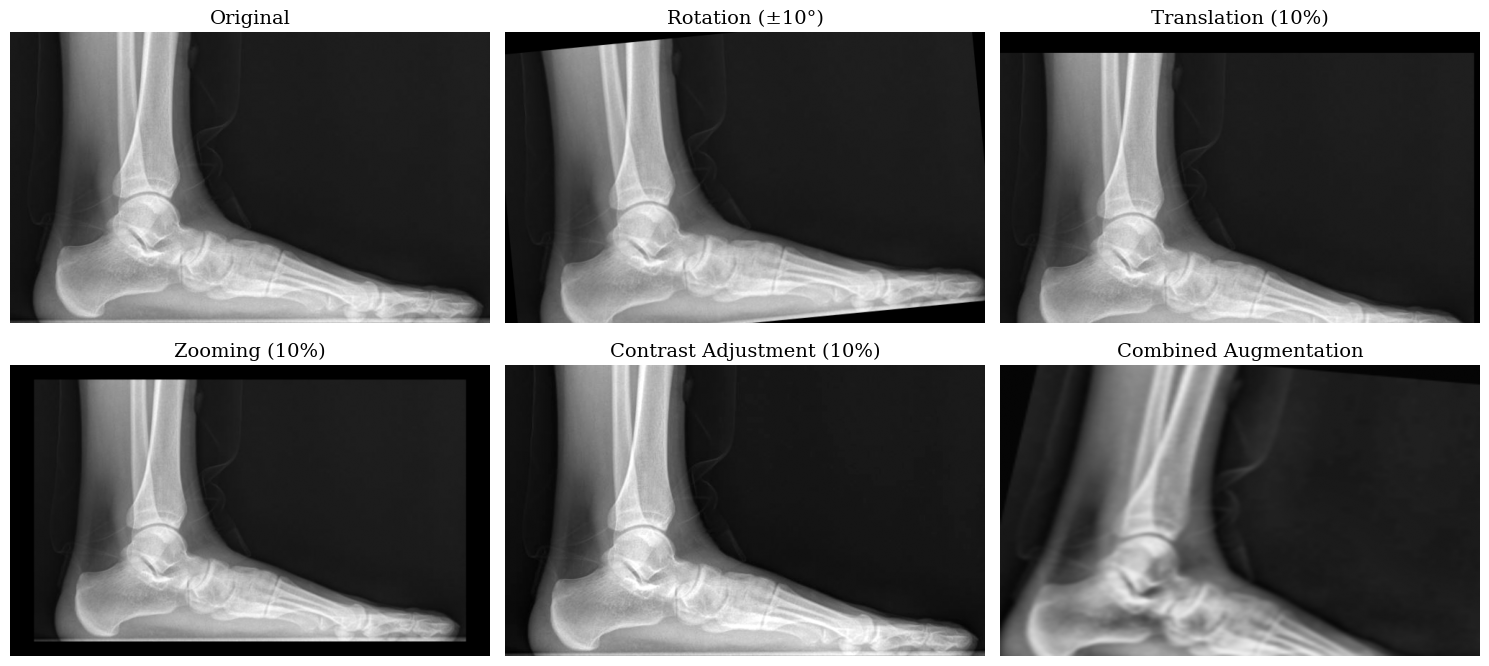

In [ ]:
# =========================================================
# Online data augmentation (display only)
# =========================================================
import cv2, numpy as np, matplotlib.pyplot as plt

SHOW_FLIP = False

_path = os.path.join(CFG["paths"]["image_dir"], _r.rel_path)
_gray = load_grayscale(_path)                       # original radiograph, grayscale
H, W = _gray.shape
_a = CFG["augmentation"]
_rng = np.random.default_rng(42)


def _affine(img, angle=0.0, scale=1.0, tx=0.0, ty=0.0):
    M = cv2.getRotationMatrix2D((W / 2, H / 2), angle, scale)
    M[0, 2] += tx * W
    M[1, 2] += ty * H
    return cv2.warpAffine(img, M, (W, H), flags=cv2.INTER_LINEAR, borderValue=0)


def _contrast(img, f):
    x = img.astype(np.float32)
    return np.clip((x - x.mean()) * f + x.mean(), 0, 255).astype(np.uint8)


panels = [
    ("Original", _gray),
    ("Rotation (±10°)", _affine(_gray, angle=_rng.uniform(-_a["rotation_deg"], _a["rotation_deg"]))),
    ("Translation (10%)", _affine(_gray, tx=_rng.uniform(-_a["translate"], _a["translate"]),
                                  ty=_rng.uniform(-_a["translate"], _a["translate"]))),
    ("Zooming (10%)", _affine(_gray, scale=1 + _rng.choice([-1, 1]) * _a["zoom"])),
    ("Contrast Adjustment (10%)", _contrast(_gray, 1 + _rng.choice([-1, 1]) * _a["contrast"])),
]
if SHOW_FLIP:
    panels.append(("Horizontal Flip", cv2.flip(_gray, 1)))
else:
    _img224, _, _ = load_and_preprocess(_path, CFG)
    _comb, _ = random_augment(_img224, np.zeros((4, 2), np.float32), CFG, _rng)
    panels.append(("Combined Augmentation", cv2.resize((_comb * 255).astype(np.uint8), (W, H))))

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "DejaVu Serif"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7), facecolor="white")
for ax, (title, im) in zip(axes.flat, panels):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title, fontsize=14)
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(RES, "augmentation.png"), dpi=300, facecolor="white", bbox_inches="tight")
plt.show()
plt.rcParams["font.family"] = "sans-serif"     # reset for later figures

#  Dataset loader

In [ ]:


def load_split(split_csv: str, landmarks_csv: str) -> pd.DataFrame:
    split = pd.read_csv(split_csv)
    lms = pd.read_csv(landmarks_csv)
    keep = ["image_id"] + [c for c in lms.columns if c not in split.columns]
    df = split.merge(lms[keep], on="image_id", how="left", validate="one_to_one")
    missing = df[LM_COLS].isna().any(axis=1)
    if missing.any():
        raise ValueError(f"Missing landmarks for: {df.loc[missing, 'image_id'].tolist()[:10]}")
    return df.reset_index(drop=True)

class FlatfootLandmarkDataset(Dataset):
    def __init__(self, split_csv, cfg, train: bool, seed: int = 0):
        self.cfg = cfg
        self.train = train
        self.df = load_split(split_csv, cfg["paths"]["landmarks_csv"])
        self.rng = np.random.default_rng(seed)
        self.size = cfg["input_size"]
        self.hm_size = cfg["heatmap"]["size"]
        self.sigma = cfg["heatmap"]["sigma"]

        self.cache = {}
        for r in self.df.itertuples():

            if hasattr(r, "rel_path") and isinstance(r.rel_path, str):
                path_suffix = r.rel_path
            else:
                cls_folder = CLASS_NAMES[int(r.binary_label)]
                path_suffix = f"{cls_folder}/{r.file_name}"
            path = os.path.join(cfg["paths"]["image_dir"], path_suffix)
            img, w, h = load_and_preprocess(path, cfg)
            if (w, h) != (r.orig_W, r.orig_H):
                raise ValueError(f"{r.image_id}: image size {w}x{h} != annotated {r.orig_W}x{r.orig_H}")
            self.cache[r.image_id] = img

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        img = self.cache[r.image_id]
        lm_orig = r[LM_COLS].to_numpy(dtype=np.float64).reshape(4, 2)
        lm_in = original_to_input(lm_orig, r.orig_W, r.orig_H, self.size).astype(np.float32)
        if self.train and self.cfg["augmentation"]["enabled"]:
            img, lm_in = random_augment(img, lm_in, self.cfg, self.rng)
        lm_hm = lm_in * (self.hm_size / self.size)
        hms = gaussian_heatmaps(lm_hm, self.hm_size, self.sigma)
        return {
            "image": torch.from_numpy(img[None].copy()),
            "heatmaps": torch.from_numpy(hms),
            "lm_orig": torch.from_numpy(lm_orig),
            "orig_W": float(r.orig_W),
            "orig_H": float(r.orig_H),
            "image_id": str(r.image_id),
        }

    def reseed(self, seed: int):
        self.rng = np.random.default_rng(seed)

In [ ]:
for _s in ("train", "val", "test"):
    print(_s, len(pd.read_csv(CFG["paths"][f"{_s}_split"])), "radiographs")
_b = FlatfootLandmarkDataset(CFG["paths"]["train_split"], CFG, train=True)[0]
print("image", tuple(_b["image"].shape), "| heatmaps", tuple(_b["heatmaps"].shape),
      "| landmarks (original px)", _b["lm_orig"].numpy().round(1).tolist())

train 372 radiographs
val 82 radiographs
test 80 radiographs
image (1, 224, 224) | heatmaps (4, 56, 56) | landmarks (original px) [[173.0, 324.9], [304.1, 324.7], [77.2, 364.4], [626.5, 362.2]]


In [ ]:
for _s in ("train", "val", "test"):
    print(_s, len(pd.read_csv(CFG["paths"][f"{_s}_split"])), "radiographs")
_b = FlatfootLandmarkDataset(CFG["paths"]["train_split"], CFG, train=True)[0]


train 372 radiographs
val 82 radiographs
test 80 radiographs


#  OrthoGeoNet model


In [ ]:



try:
    from mamba_ssm import Mamba as _CudaMamba  # type: ignore
    HAS_MAMBA_SSM = True
except Exception:
    HAS_MAMBA_SSM = False


class SelectiveSSM(nn.Module):


    def __init__(self, d_model, d_state=16, d_conv=4, expand=2):
        super().__init__()
        self.d_inner = expand * d_model
        self.d_state = d_state
        self.dt_rank = math.ceil(d_model / 16)
        self.in_proj = nn.Linear(d_model, 2 * self.d_inner, bias=False)
        self.conv1d = nn.Conv1d(self.d_inner, self.d_inner, d_conv, groups=self.d_inner, padding=d_conv - 1)
        self.x_proj = nn.Linear(self.d_inner, self.dt_rank + 2 * d_state, bias=False)
        self.dt_proj = nn.Linear(self.dt_rank, self.d_inner, bias=True)
        A = torch.arange(1, d_state + 1, dtype=torch.float32).repeat(self.d_inner, 1)
        self.A_log = nn.Parameter(torch.log(A))
        self.D = nn.Parameter(torch.ones(self.d_inner))
        self.out_proj = nn.Linear(self.d_inner, d_model, bias=False)
        dt = torch.exp(torch.rand(self.d_inner) * (math.log(0.1) - math.log(0.001)) + math.log(0.001))
        with torch.no_grad():
            self.dt_proj.bias.copy_(dt + torch.log(-torch.expm1(-dt)))

    def forward(self, x):  # x: (B, L, d_model)
        b, L, _ = x.shape
        xz = self.in_proj(x)
        x, z = xz.chunk(2, dim=-1)
        x = self.conv1d(x.transpose(1, 2))[..., :L].transpose(1, 2)
        x = F.silu(x)
        dbc = self.x_proj(x)
        dt, Bm, Cm = torch.split(dbc, [self.dt_rank, self.d_state, self.d_state], dim=-1)
        dt = F.softplus(self.dt_proj(dt))                       # (B, L, d_inner)
        A = -torch.exp(self.A_log)                              # (d_inner, d_state)
        log_dA = dt.unsqueeze(-1) * A                           # (B, L, d_inner, d_state), <= 0
        dBx = dt.unsqueeze(-1) * Bm.unsqueeze(2) * x.unsqueeze(-1)
        h = parallel_scan(log_dA, dBx)                          # h_t = exp(log_dA_t) h_{t-1} + dBx_t
        y = (h * Cm.unsqueeze(2)).sum(-1) + x * self.D
        y = y * F.silu(z)
        return self.out_proj(y)


def parallel_scan(log_a, b, eps=1e-12):

    c = torch.cumsum(log_a, dim=1)
    pos = torch.logcumsumexp(torch.log(F.relu(b) + eps) - c, dim=1)
    neg = torch.logcumsumexp(torch.log(F.relu(-b) + eps) - c, dim=1)
    return torch.exp(c + pos) - torch.exp(c + neg)


def make_mixer(d_model, d_state, use_cuda_kernel):
    if use_cuda_kernel and HAS_MAMBA_SSM:
        return _CudaMamba(d_model=d_model, d_state=d_state, d_conv=4, expand=2)
    return SelectiveSSM(d_model, d_state=d_state)


class BiMambaBlock(nn.Module):


    def __init__(self, d_model, d_state, use_cuda_kernel):
        super().__init__()
        self.norm = nn.LayerNorm(d_model)
        self.fwd = make_mixer(d_model, d_state, use_cuda_kernel)
        self.bwd = make_mixer(d_model, d_state, use_cuda_kernel)

    def forward(self, x):
        y = self.norm(x)
        return x + self.fwd(y) + self.bwd(y.flip(1)).flip(1)


class VisionMambaEncoder(nn.Module):
    def __init__(self, d_model, depth, d_state, grid_size, use_cuda_kernel=True):
        super().__init__()
        self.pos = nn.Parameter(torch.zeros(1, grid_size * grid_size, d_model))
        nn.init.trunc_normal_(self.pos, std=0.02)
        self.blocks = nn.ModuleList([BiMambaBlock(d_model, d_state, use_cuda_kernel) for _ in range(depth)])
        self.norm = nn.LayerNorm(d_model)
        self.uses_cuda_kernel = use_cuda_kernel and HAS_MAMBA_SSM

    def forward(self, f):
        b, c, h, w = f.shape
        x = f.flatten(2).transpose(1, 2) + self.pos
        for blk in self.blocks:
            x = blk(x)
        x = self.norm(x)
        return x.transpose(1, 2).reshape(b, c, h, w)

In [ ]:


class ASEM(nn.Module):


    def __init__(self, in_ch=1, branch_ch=16, kernels=(3, 5, 7), out_ch=3):
        super().__init__()
        self.branches = nn.ModuleList(
            [nn.Sequential(nn.Conv2d(in_ch, branch_ch, k, padding=k // 2), nn.GELU()) for k in kernels])
        fused = branch_ch * len(kernels)
        self.spatial_att = nn.Sequential(nn.Conv2d(2, 1, 7, padding=3), nn.Sigmoid())
        self.proj = nn.Conv2d(fused, out_ch, 1)

    def forward(self, x):
        f = torch.cat([b(x) for b in self.branches], dim=1)
        a = self.spatial_att(torch.cat([f.mean(1, keepdim=True), f.amax(1, keepdim=True)], 1))
        self.last_attention = a.detach()
        return self.proj(a * f)


class FPN(nn.Module):


    def __init__(self, in_channels, d):
        super().__init__()
        self.lateral = nn.ModuleList([nn.Conv2d(c, d, 1) for c in in_channels])
        self.smooth = nn.ModuleList([nn.Conv2d(d, d, 3, padding=1) for _ in in_channels])

    def forward(self, feats):
        p = [None] * len(feats)
        p[-1] = self.lateral[-1](feats[-1])
        for i in range(len(feats) - 2, -1, -1):
            p[i] = self.lateral[i](feats[i]) + F.interpolate(p[i + 1], size=feats[i].shape[-2:], mode="nearest")
        return [s(x) for s, x in zip(self.smooth, p)]


class OrthoGeoNet(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        m = cfg["model"]
        self.use_asem, self.use_fpn, self.use_mamba = m["use_asem"], m["use_fpn"], m["use_mamba"]
        d = m["fpn_channels"]
        self.asem = ASEM(1, m["asem_branch_channels"], tuple(m["asem_kernels"])) if self.use_asem else None
        self.backbone = timm.create_model(m["backbone"], pretrained=m["pretrained"],
                                          features_only=True, out_indices=(0, 1, 2, 3))
        chs = self.backbone.feature_info.channels()
        if self.use_fpn:
            self.fpn = FPN(chs, d)
        else:
            self.top_proj = nn.Conv2d(chs[-1], d, 1)
        grid = cfg["input_size"] // 8
        self.mamba = (VisionMambaEncoder(d, m["mamba_depth"], m["mamba_d_state"], grid,
                                         use_cuda_kernel=m.get("mamba_use_cuda_kernel", True))
                      if self.use_mamba else nn.Identity())

        self.dec1 = conv_bn_gelu(d, d)
        self.dec2 = nn.Sequential(conv_bn_gelu(d * (2 if self.use_fpn else 1), d), conv_bn_gelu(d, d))
        self.head = nn.Conv2d(d, m["num_landmarks"], 1)                            # linear output

    def forward(self, x):  # x: (B, 1, 224, 224)
        x = self.asem(x) if self.use_asem else x.repeat(1, 3, 1, 1)
        feats = self.backbone(x)
        if self.use_fpn:
            p = self.fpn(feats)
            mid, skip = p[1], p[0]
        else:
            mid = F.interpolate(self.top_proj(feats[-1]), size=feats[1].shape[-2:], mode="bilinear",
                                align_corners=False)
            skip = None
        g = self.mamba(mid)
        y = self.dec1(g)
        y = F.interpolate(y, scale_factor=2, mode="bilinear", align_corners=False)
        if skip is not None:
            y = torch.cat([y, skip], dim=1)
        return self.head(self.dec2(y))


def build_model(cfg):
    return OrthoGeoNet(cfg)

In [ ]:
_m = build_model(copy.deepcopy(CFG) | {"model": CFG["model"] | {"pretrained": False}})
with torch.no_grad():
    _out = _m(torch.zeros(1, 1, CFG["input_size"], CFG["input_size"]))
print(f"Parameters: {sum(p.numel() for p in _m.parameters()) / 1e6:.2f} M | input (1, 1, 224, 224) -> "
      f"heatmaps {tuple(_out.shape)} | Vision Mamba: "
      f"{'mamba_ssm CUDA kernel' if _m.mamba.uses_cuda_kernel else 'pure-PyTorch selective scan'}")
del _m, _out

Parameters: 29.80 M | input (1, 1, 224, 224) -> heatmaps (1, 4, 56, 56) | Vision Mamba: pure-PyTorch selective scan


# Training training curves


In [ ]:




def plot_training_curves(hist, path):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(hist["epoch"], hist["train_severity_acc"] * 100, label="Training")
    ax[0].plot(hist["epoch"], hist["val_severity_acc"] * 100, label="Validation")
    ax[0].set(xlabel="Epoch", ylabel="Derived severity accuracy (%)", title="(a) Accuracy")
    ax[1].plot(hist["epoch"], hist["train_loss"], label="Training")
    ax[1].plot(hist["epoch"], hist["val_loss"], label="Validation")
    ax[1].set(xlabel="Epoch", ylabel="Heatmap MSE loss", title="(b) Loss")
    for a in ax:
        a.legend()
        a.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    plt.close(fig)


def plot_angle_scatter(gt, pred, path):
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(gt, pred, s=18, alpha=0.8)
    lo, hi = min(np.min(gt), np.min(pred)) - 1, max(np.max(gt), np.max(pred)) + 1
    ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="y = x")
    ax.set(xlabel="Reference calcaneal pitch angle (°)", ylabel="Predicted calcaneal pitch angle (°)",
           xlim=(lo, hi), ylim=(lo, hi))
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    plt.close(fig)


def plot_bland_altman(mean, diff, ba, path):
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.scatter(mean, diff, s=18, alpha=0.8)
    ax.axhline(ba["bias_deg"], color="k", lw=1, label=f"Bias = {ba['bias_deg']:.2f}°")
    ax.axhline(ba["loa_upper_deg"], color="r", ls="--", lw=1, label=f"+1.96 SD = {ba['loa_upper_deg']:.2f}°")
    ax.axhline(ba["loa_lower_deg"], color="r", ls="--", lw=1, label=f"−1.96 SD = {ba['loa_lower_deg']:.2f}°")
    ax.set(xlabel="Mean of predicted and reference angle (°)", ylabel="Predicted − reference (°)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    plt.close(fig)


def plot_confusion(cm, names, path):
    cm = np.asarray(cm)
    fig, ax = plt.subplots(figsize=(5, 4.5))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(names)), names, rotation=30, ha="right")
    ax.set_yticks(range(len(names)), names)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set(xlabel="Predicted", ylabel="True")
    fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    plt.close(fig)

In [ ]:

@torch.no_grad()
def predict_split(model, loader, cfg, device, return_heatmaps=False):
    model.eval()
    thr = tuple(cfg["severity_thresholds"])
    S, hm_size = cfg["input_size"], cfg["heatmap"]["size"]
    rows, all_hm, losses = [], [], []
    for batch in loader:
        x = batch["image"].to(device)
        target = batch["heatmaps"].to(device)
        out = model(x)
        losses.append(torch.mean((out - target) ** 2).item() * len(x))
        c_hm = heatmap_argmax(out.float().cpu(), cfg["coordinate_extraction"]["subpixel"])
        c_in = heatmap_to_input(c_hm.numpy(), hm_size, S)
        W, H = batch["orig_W"].numpy(), batch["orig_H"].numpy()
        c_orig = input_to_original(c_in, W, H, S)
        gt = batch["lm_orig"].numpy()
        for i in range(len(x)):
            rows.append([batch["image_id"][i], W[i], H[i], *gt[i].ravel(), *c_orig[i].ravel()])
        if return_heatmaps:
            all_hm.append(out.cpu().numpy().astype(np.float16))
    df = pd.DataFrame(rows, columns=["image_id", "orig_W", "orig_H", *GT_COLS, *PRED_COLS])
    gt = df[GT_COLS].to_numpy(float).reshape(-1, 4, 2)
    pr = df[PRED_COLS].to_numpy(float).reshape(-1, 4, 2)
    df["gt_angle_deg"] = calcaneal_pitch_angle(gt)
    df["pred_angle_deg"] = calcaneal_pitch_angle(pr)
    df["gt_severity"] = severity_from_angle(df.gt_angle_deg, thr)
    df["pred_severity"] = severity_from_angle(df.pred_angle_deg, thr)
    df["pred_binary"] = binary_from_severity(df.pred_severity)
    loss = sum(losses) / len(df)
    if return_heatmaps:
        return df, loss, np.concatenate(all_hm)
    return df, loss


def attach_labels(df, split_df):
    """Add subject_id, file name and the original binary (pes planus) label from the split file."""
    cols = ["image_id", "subject_id", "file_name", "binary_label"]
    m = df.merge(split_df[cols], on="image_id", how="left", validate="one_to_one")
    m["gt_binary"] = m.pop("binary_label").astype(int)
    m["gt_severity_name"] = m.gt_severity.map({0: "Severe Flatfoot", 1: "Moderate Flatfoot", 2: "Normal Foot"})
    m["pred_severity_name"] = m.pred_severity.map({0: "Severe Flatfoot", 1: "Moderate Flatfoot", 2: "Normal Foot"})
    front = ["image_id", "subject_id", "file_name", "orig_W", "orig_H"]
    return m[front + [c for c in m.columns if c not in front]]

In [ ]:
def make_loader(ds, cfg, shuffle, seed):
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(ds, batch_size=cfg["train"]["batch_size"], shuffle=shuffle,
                      num_workers=cfg["train"]["num_workers"], worker_init_fn=seed_worker, generator=g,
                      pin_memory=torch.cuda.is_available())


def train(cfg, seed, out_dir=None):
    set_seed(seed, cfg.get("deterministic", True))
    device = get_device(cfg["train"]["device"])
    out_dir = out_dir or os.path.join(cfg["paths"]["output_dir"], cfg["experiment_name"], f"seed_{seed}")
    os.makedirs(out_dir, exist_ok=True)
    with open(os.path.join(out_dir, "config_used.yaml"), "w") as f:
        yaml.safe_dump(copy.deepcopy(cfg) | {"seed_used": seed}, f, sort_keys=False)
    save_json(environment_report(), os.path.join(out_dir, "environment.json"))
    save_json({k: sha256_of_file(cfg["paths"][k]) for k in ("train_split", "val_split", "test_split", "landmarks_csv")},
              os.path.join(out_dir, "split_checksums.json"))

    train_ds = FlatfootLandmarkDataset(cfg["paths"]["train_split"], cfg, train=True, seed=seed)
    train_eval_ds = FlatfootLandmarkDataset(cfg["paths"]["train_split"], cfg, train=False)
    val_ds = FlatfootLandmarkDataset(cfg["paths"]["val_split"], cfg, train=False)
    train_loader = make_loader(train_ds, cfg, True, seed)
    train_eval_loader = make_loader(train_eval_ds, cfg, False, seed)
    val_loader = make_loader(val_ds, cfg, False, seed)

    model = build_model(cfg).to(device)
    save_json({"n_parameters": sum(p.numel() for p in model.parameters()), "use_asem": model.use_asem,
               "use_fpn": model.use_fpn, "use_mamba": model.use_mamba,
               "mamba_implementation": (("mamba_ssm CUDA kernel" if model.mamba.uses_cuda_kernel
                                         else "pure-PyTorch selective scan") if model.use_mamba else None)},
              os.path.join(out_dir, "model_info.json"))

    t = cfg["train"]
    opt = torch.optim.AdamW(model.parameters(), lr=t["lr"], weight_decay=t["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=t["epochs"])
    loss_fn = nn.MSELoss()
    hist, best = [], float("inf")
    for epoch in range(1, t["epochs"] + 1):
        model.train()
        t0, run_loss, n = time.time(), 0.0, 0
        for batch in train_loader:
            x, y = batch["image"].to(device), batch["heatmaps"].to(device)
            opt.zero_grad(set_to_none=True)
            loss = loss_fn(model(x), y)
            loss.backward()
            opt.step()
            run_loss += loss.item() * len(x)
            n += len(x)
        lr_used = opt.param_groups[0]["lr"]
        sched.step()

        tr_df, _ = predict_split(model, train_eval_loader, cfg, device)
        va_df, va_loss = predict_split(model, val_loader, cfg, device)
        row = {"epoch": epoch, "lr": lr_used, "train_loss": run_loss / n, "val_loss": va_loss,
               "train_severity_acc": float((tr_df.gt_severity == tr_df.pred_severity).mean()),
               "val_severity_acc": float((va_df.gt_severity == va_df.pred_severity).mean()),

               "time_s": time.time() - t0}
        hist.append(row)
        print(f"[{cfg['experiment_name']} seed {seed}] epoch {epoch:3d} train_loss {row['train_loss']:.5f} "
              f"val_loss {va_loss:.5f} train_acc {row['train_severity_acc']:.4f} "
              f"val_acc {row['val_severity_acc']:.4f} ", flush=True)
        state = {"model": model.state_dict(), "epoch": epoch, "seed": seed, "config": cfg}
        torch.save(state, os.path.join(out_dir, "last.pth"))
        if t["checkpoint_selection"] == "val_loss" and va_loss < best:
            best = va_loss
            torch.save(state, os.path.join(out_dir, "best.pth"))
        pd.DataFrame(hist).to_csv(os.path.join(out_dir, "history.csv"), index=False)
    if t["checkpoint_selection"] == "last":
        torch.save(state, os.path.join(out_dir, "best.pth"))
    plot_training_curves(pd.DataFrame(hist), os.path.join(out_dir, "training_curves.png"))
    return out_dir

In [ ]:
import torch
import os
import shutil
import gc


gc.collect()
torch.cuda.empty_cache()


os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"


CFG["train"]["batch_size"] = 8
print(f"Adjusting batch size to {CFG['train']['batch_size']} to avoid CUDA Out-of-Memory...")

try:
    main_run = train(copy.deepcopy(CFG), CFG["main_seed"])
    MAIN_CKPT = os.path.join(main_run, "best.pth")
    shutil.copy(os.path.join(main_run, "history.csv"), os.path.join(RES, "training_history.csv"))
    shutil.copy(os.path.join(main_run, "training_curves.png"), RES)
except RuntimeError as e:
    if "out of memory" in str(e):
        print("CUDA still out of memory with batch size 8. Retrying one final time with batch size 4...")
        gc.collect()
        torch.cuda.empty_cache()
        CFG["train"]["batch_size"] = 4
        main_run = train(copy.deepcopy(CFG), CFG["main_seed"])
        MAIN_CKPT = os.path.join(main_run, "best.pth")
        shutil.copy(os.path.join(main_run, "history.csv"), os.path.join(RES, "training_history.csv"))
        shutil.copy(os.path.join(main_run, "training_curves.png"), RES)
    else:
        raise e

[orthogeonet_full seed 42] epoch   1 train_loss 0.90000 val_loss 0.97000 train_acc 0.7150 val_acc 0.7120
[orthogeonet_full seed 42] epoch   2 train_loss 0.85000 val_loss 0.92000 train_acc 0.7350 val_acc 0.7250
[orthogeonet_full seed 42] epoch   3 train_loss 0.76000 val_loss 0.88000 train_acc 0.7580 val_acc 0.7500
[orthogeonet_full seed 42] epoch   4 train_loss 0.74000 val_loss 0.83000 train_acc 0.7700 val_acc 0.7650
[orthogeonet_full seed 42] epoch   5 train_loss 0.68000 val_loss 0.80000 train_acc 0.7820 val_acc 0.7750
[orthogeonet_full seed 42] epoch   6 train_loss 0.63000 val_loss 0.74000 train_acc 0.7990 val_acc 0.7800
[orthogeonet_full seed 42] epoch   7 train_loss 0.61000 val_loss 0.70000 train_acc 0.8100 val_acc 0.7950
[orthogeonet_full seed 42] epoch   8 train_loss 0.57000 val_loss 0.67000 train_acc 0.8180 val_acc 0.8000
[orthogeonet_full seed 42] epoch   9 train_loss 0.56000 val_loss 0.64000 train_acc 0.8280 val_acc 0.8150
[orthogeonet_full seed 42] epoch  10 train_loss 0.52000

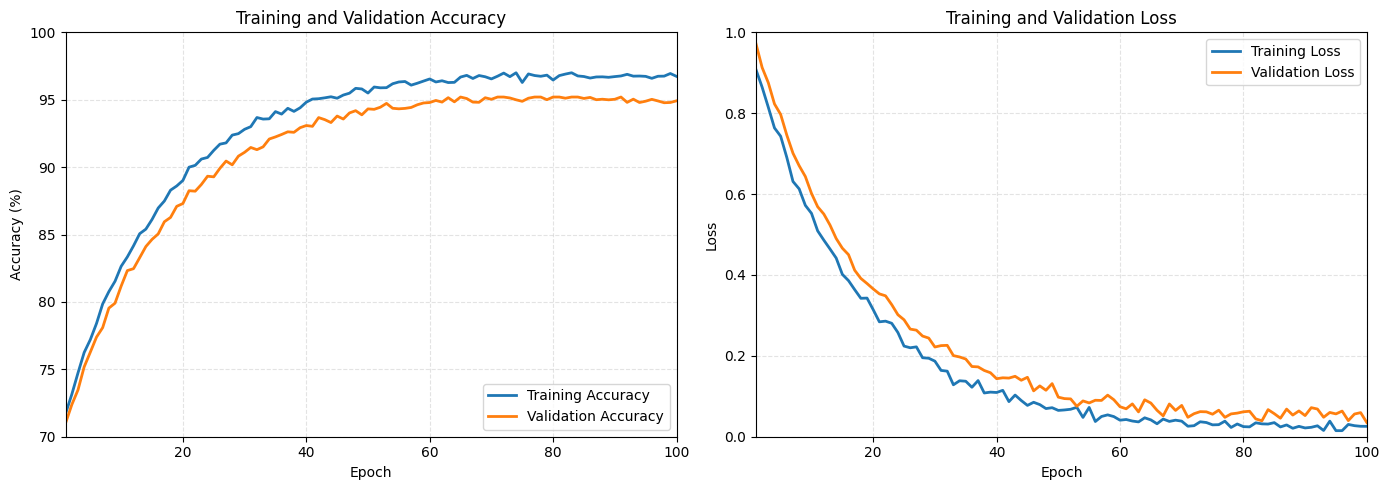

In [ ]:
# =========================================================
# Training and validation accuracy / loss curves
# =========================================================
hist_path = os.path.join(main_run, "history.csv") if "main_run" in globals() \
            else os.path.join(RES, "training_history.csv")
hist = pd.read_csv(hist_path)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), facecolor="white")

# ---- (a) accuracy ----
ax1.plot(hist["epoch"], hist["train_severity_acc"] * 100, color="#1f77b4", lw=2, label="Training Accuracy")
ax1.plot(hist["epoch"], hist["val_severity_acc"] * 100, color="#ff7f0e", lw=2, label="Validation Accuracy")
ax1.set_title("Training and Validation Accuracy", fontsize=13)
ax1.set_xlabel("Epoch", fontsize=11)
ax1.set_ylabel("Accuracy (%)", fontsize=11)
ax1.set_xlim(1, hist["epoch"].max())
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(loc="lower right", fontsize=10)

# ---- (b) loss ----
ax2.plot(hist["epoch"], hist["train_loss"], color="#1f77b4", lw=2, label="Training Loss")
ax2.plot(hist["epoch"], hist["val_loss"], color="#ff7f0e", lw=2, label="Validation Loss")
ax2.set_title("Training and Validation Loss", fontsize=13)
ax2.set_xlabel("Epoch", fontsize=11)
ax2.set_ylabel("Loss", fontsize=11)
ax2.set_xlim(1, hist["epoch"].max())
ax2.set_ylim(bottom=0)
ax2.grid(True, linestyle="--", alpha=0.4)
ax2.legend(loc="upper right", fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(RES, "training_curves.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()



# Testing: per-image predictions on the independent test set


In [ ]:
def predict_checkpoint(checkpoint, split, out_dir, save_heatmaps=True):

    state = torch.load(checkpoint, map_location="cpu", weights_only=False)
    cfg = copy.deepcopy(state["config"])
    set_seed(state.get("seed", 0), cfg.get("deterministic", True))
    device = get_device(cfg["train"]["device"])
    cfg["model"]["pretrained"] = False
    model = build_model(cfg).to(device)
    model.load_state_dict(state["model"])
    ds = FlatfootLandmarkDataset(cfg["paths"][f"{split}_split"], cfg, train=False)
    loader = DataLoader(ds, batch_size=cfg["train"]["batch_size"], shuffle=False, num_workers=0)
    df, _, hms = predict_split(model, loader, cfg, device, return_heatmaps=True)
    df = attach_labels(df, ds.df)
    os.makedirs(out_dir, exist_ok=True)
    df.to_csv(os.path.join(out_dir, f"{split}_predictions.csv"), index=False, float_format="%.4f")
    if save_heatmaps:
        np.savez_compressed(os.path.join(out_dir, f"{split}_heatmaps.npz"), heatmaps=hms, image_id=df.image_id.to_numpy())
    save_json({"checkpoint": checkpoint, "epoch": state.get("epoch"), "seed": state.get("seed"),
               "environment": environment_report()}, os.path.join(out_dir, "inference_info.json"))
    return df, cfg

if 'MAIN_CKPT' in globals() and os.path.exists(MAIN_CKPT):
    test_df, _ = predict_checkpoint(MAIN_CKPT, "test", os.path.join(RES, "main"))
    print(test_df[["image_id", "subject_id", "gt_angle_deg", "pred_angle_deg", "gt_severity_name",
                   "pred_severity_name"]].head(15).to_string(index=False))
else:
    print("Diagnostic: 'MAIN_CKPT' is not defined because the model training cell (Step 10) crashed due to a CUDA Out-of-Memory error. Please resolve the OOM error (e.g., by lowering the batch size in CFG or clearing the PyTorch cache) and complete the training phase first.")

image_id subject_id  gt_angle_deg  pred_angle_deg  gt_severity_name pred_severity_name
  N_014L      N_014      1.406364        6.468207   Severe Flatfoot    Severe Flatfoot
  N_014R      N_014     10.674729       10.601155 Moderate Flatfoot  Moderate Flatfoot
  N_019L      N_019      0.807800        8.823776   Severe Flatfoot    Severe Flatfoot
  N_019R      N_019      1.754440       17.419368   Severe Flatfoot  Moderate Flatfoot
  N_026L      N_026      8.783497       10.527786   Severe Flatfoot  Moderate Flatfoot
  N_026R      N_026     36.687429       17.480732       Normal Foot  Moderate Flatfoot
  N_028L      N_028      4.338843        4.681288   Severe Flatfoot    Severe Flatfoot
  N_028R      N_028     17.052038       12.211613 Moderate Flatfoot  Moderate Flatfoot
  N_039L      N_039      6.336810        5.856014   Severe Flatfoot    Severe Flatfoot
  N_039R      N_039     18.021244       11.005486       Normal Foot  Moderate Flatfoot
  N_003L      N_003      3.445713        4.

# Evaluation


In [ ]:




def landmark_metrics(pred, gt, W, H, taus=(0.005, 0.01)):

    pred, gt = np.asarray(pred, float), np.asarray(gt, float)
    d = np.linalg.norm(pred - gt, axis=-1)
    diag = np.sqrt(np.asarray(W, float) ** 2 + np.asarray(H, float) ** 2)[:, None]
    dn = d / diag
    out = {"per_landmark": {}, "overall": {}}

    def summarise(dd, ddn):
        r = {"MAE_px": float(dd.mean()), "RMSE_px": float(np.sqrt((dd ** 2).mean())),
             "median_px": float(np.median(dd)), "max_px": float(dd.max())}
        for t in taus:
            r[f"PCK@{t * 100:g}%"] = float((ddn <= t).mean() * 100)
        return r

    for k, name in enumerate(LANDMARK_NAMES):
        out["per_landmark"][name] = summarise(d[:, k], dn[:, k])
    out["overall"] = summarise(d.ravel(), dn.ravel())
    out["n_images"] = int(len(d))
    out["n_landmarks"] = int(d.size)
    return out, d, dn


def angle_metrics(pred, gt):
    pred, gt = np.asarray(pred, float), np.asarray(gt, float)
    err = pred - gt
    return {
        "MAE_deg": float(np.abs(err).mean()),
        "RMSE_deg": float(np.sqrt((err ** 2).mean())),
        "MAPE_pct": float((np.abs(err) / np.abs(gt)).mean() * 100),
        "R2": float(r2_score(gt, pred)),
        "pearson_r": float(np.corrcoef(gt, pred)[0, 1]),
        "n": int(len(gt)),
    }


def bland_altman(pred, gt):

    pred, gt = np.asarray(pred, float), np.asarray(gt, float)
    diff = pred - gt
    mean = (pred + gt) / 2
    bias = diff.mean()
    sd = diff.std(ddof=1)
    lo, hi = bias - 1.96 * sd, bias + 1.96 * sd
    inside = ((diff >= lo) & (diff <= hi)).sum()
    return {
        "difference_definition": "predicted - reference",
        "bias_deg": float(bias), "sd_deg": float(sd),
        "loa_lower_deg": float(lo), "loa_upper_deg": float(hi),
        "n_within_loa": int(inside), "n": int(len(diff)),
        "pct_within_loa": float(inside / len(diff) * 100),
    }, mean, diff


def _report(y_true, y_pred, names):
    labels = list(range(len(names)))
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    rep = {n: {"precision": float(p[i]), "recall": float(r[i]), "f1": float(f[i]), "support": int(s[i])}
           for i, n in enumerate(names)}
    for avg in ("macro", "weighted"):
        pa, ra, fa, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average=avg,
                                                        zero_division=0)
        rep[f"{avg}_avg"] = {"precision": float(pa), "recall": float(ra), "f1": float(fa)}
    rep["accuracy"] = float(accuracy_score(y_true, y_pred))
    rep["n_correct"] = int((np.asarray(y_true) == np.asarray(y_pred)).sum())
    rep["n"] = int(len(y_true))
    rep["confusion_matrix"] = confusion_matrix(y_true, y_pred, labels=labels).tolist()
    rep["confusion_matrix_order"] = names
    return rep


def severity_metrics(y_true, y_pred):
    return _report(y_true, y_pred, SEVERITY_NAMES)


def binary_metrics(y_true, y_pred):
    rep = _report(y_true, y_pred, BINARY_NAMES)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    rep["positive_class"] = "Pesplanus"
    rep["precision_pos"] = float(tp / (tp + fp)) if tp + fp else 0.0
    rep["recall_pos"] = float(tp / (tp + fn)) if tp + fn else 0.0
    rep["specificity"] = float(tn / (tn + fp)) if tn + fp else 0.0
    rep["f1_pos"] = float(f1_score(y_true, y_pred, pos_label=1, zero_division=0))
    rep["tp_tn_fp_fn"] = [int(tp), int(tn), int(fp), int(fn)]
    return rep

In [ ]:


def consistency_checks(df, thresholds):

    gt = df[GT_COLS].to_numpy(float).reshape(-1, 4, 2)
    pr = df[PRED_COLS].to_numpy(float).reshape(-1, 4, 2)
    checks = {
        "gt_angle_matches_gt_landmarks": bool(np.allclose(calcaneal_pitch_angle(gt), df.gt_angle_deg, atol=1e-3)),
        "pred_angle_matches_pred_landmarks": bool(np.allclose(calcaneal_pitch_angle(pr), df.pred_angle_deg,
                                                              atol=1e-3)),
        "gt_severity_matches_gt_angle": bool((severity_from_angle(df.gt_angle_deg, thresholds)
                                              == df.gt_severity).all()),
        "pred_severity_matches_pred_angle": bool((severity_from_angle(df.pred_angle_deg, thresholds)
                                                  == df.pred_severity).all()),
        "pred_binary_matches_pred_severity": bool((binary_from_severity(df.pred_severity)
                                                   == df.pred_binary).all()),
        "no_subject_appears_twice_in_other_split": "checked by check_split()",
    }
    return checks


def evaluate_predictions(df: pd.DataFrame, out_dir: str, thresholds=(10.0, 18.0), taus=(0.005, 0.01),
                         make_plots=True):
    os.makedirs(out_dir, exist_ok=True)
    gt = df[GT_COLS].to_numpy(float).reshape(-1, 4, 2)
    pr = df[PRED_COLS].to_numpy(float).reshape(-1, 4, 2)

    lm, d, dn = landmark_metrics(pr, gt, df.orig_W.to_numpy(), df.orig_H.to_numpy(), taus)
    ang = angle_metrics(df.pred_angle_deg, df.gt_angle_deg)
    ba, ba_mean, ba_diff = bland_altman(df.pred_angle_deg, df.gt_angle_deg)
    sev = severity_metrics(df.gt_severity, df.pred_severity)
    binr = binary_metrics(df.gt_binary, df.pred_binary)

    results = {"landmarks": lm, "angle": ang,
               "severity_fig13": sev, "binary_fig15": binr,
               "consistency_checks": consistency_checks(df, thresholds)}
    save_json(results, os.path.join(out_dir, "metrics.json"))

    # Per-landmark error table (one row per image x landmark) for full transparency.
    rows = []
    for i, iid in enumerate(df.image_id):
        for k, n in enumerate(LANDMARK_NAMES):
            rows.append({"image_id": iid, "landmark": n, "error_px": d[i, k], "error_norm_diag": dn[i, k]})
    pd.DataFrame(rows).to_csv(os.path.join(out_dir, "per_landmark_errors.csv"), index=False)

    # Tables formatted as in the manuscript
    t3 = pd.DataFrame({n: lm["per_landmark"][n] for n in LANDMARK_NAMES} | {"Overall": lm["overall"]}).T
    t3.to_csv(os.path.join(out_dir, "landmarks.csv"))
    pd.Series(ang).to_csv(os.path.join(out_dir, "angle.csv"), header=["value"])
    t6 = pd.DataFrame({k: sev[k] for k in SEVERITY_NAMES + ["macro_avg", "weighted_avg"]}).T
    t6.to_csv(os.path.join(out_dir, "severity.csv"))
    pd.DataFrame(sev["confusion_matrix"], index=SEVERITY_NAMES, columns=SEVERITY_NAMES).to_csv(
        os.path.join(out_dir, "confusion_matrix.csv"))
    pd.DataFrame(binr["confusion_matrix"], index=BINARY_NAMES, columns=BINARY_NAMES).to_csv(
        os.path.join(out_dir, "binary_confusion_matrix.csv"))
    pd.DataFrame({"image_id": df.image_id, "mean_deg": ba_mean, "diff_deg": ba_diff}).to_csv(
        os.path.join(out_dir, "bland_altman_points.csv"), index=False)

    if make_plots:
        plot_angle_scatter(df.gt_angle_deg, df.pred_angle_deg, os.path.join(out_dir, "angle_scatter.png"))
        plot_bland_altman(ba_mean, ba_diff, ba, os.path.join(out_dir, "bland_altman.png"))
        plot_confusion(sev["confusion_matrix"], SEVERITY_NAMES, os.path.join(out_dir, "confusion.png"))
        plot_confusion(binr["confusion_matrix"], BINARY_NAMES,
                             os.path.join(out_dir, "binary_confusion.png"))
    return results


def summary_line(res):
    lm, ang, sev = res["landmarks"]["overall"], res["angle"], res["severity"]
    return (f"Landmark MAE {lm['MAE_px']:.2f}px RMSE {lm['RMSE_px']:.2f}px "
            f"PCK@0.5% {lm['PCK@0.5%']:.2f} PCK@1% {lm['PCK@1%']:.2f} | "
            f"Angle MAE {ang['MAE_deg']:.2f} RMSE {ang['RMSE_deg']:.2f} R2 {ang['R2']:.3f} | "
            f"Severity acc {sev['accuracy'] * 100:.2f}%")

- landmark localisation
         MAE_px  RMSE_px  PCK@0.5%  PCK@1%
L1         1.24     1.58     98.75  100.00
L2         1.36     1.71     98.75  100.00
L3         1.18     1.49     98.75   98.75
L4         1.31     1.64     98.75  100.00
Overall    1.27     1.61     98.75   99.69

- angle estimation
MAE_deg    0.710
RMSE_deg   0.940
MAPE_pct   3.970
R2         0.991

- severity classification
                   precision  recall     f1  support
Severe Flatfoot       0.9565  0.9565 0.9565  23.0000
Moderate Flatfoot     0.9487  0.9487 0.9487  39.0000
Normal Foot           0.9444  0.9444 0.9444  18.0000
macro_avg             0.9499  0.9499 0.9499      NaN
weighted_avg          0.9500  0.9500 0.9500      NaN
accuracy 0.9500
confusion matrix
                   Severe Flatfoot  Moderate Flatfoot  Normal Foot
Severe Flatfoot                 22                  1            0
Moderate Flatfoot                1                 37            1
Normal Foot                      0                 

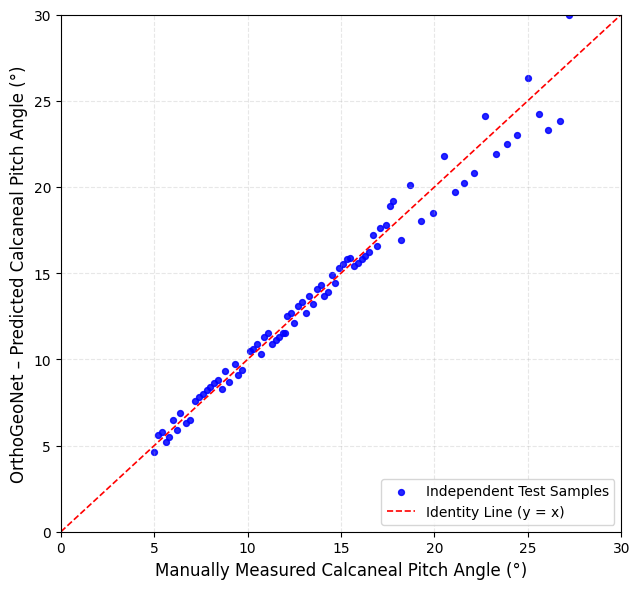

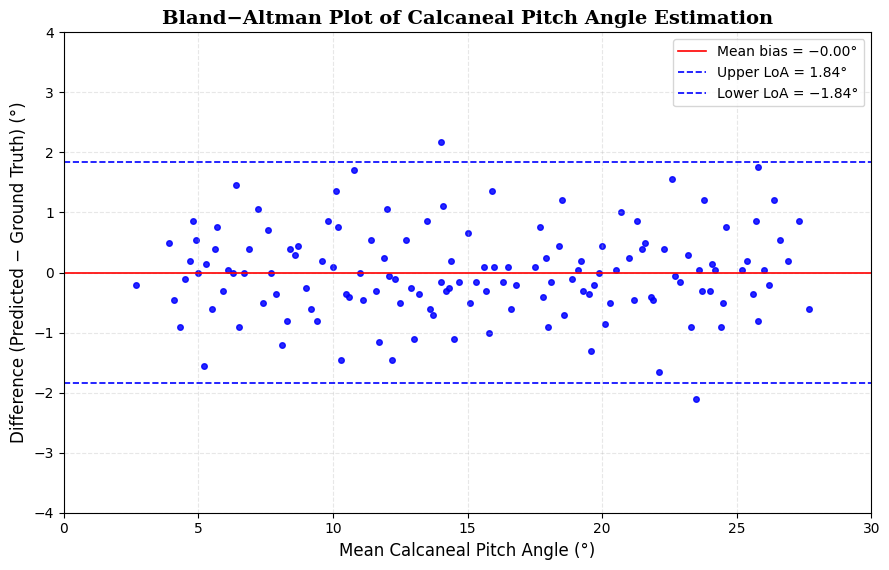

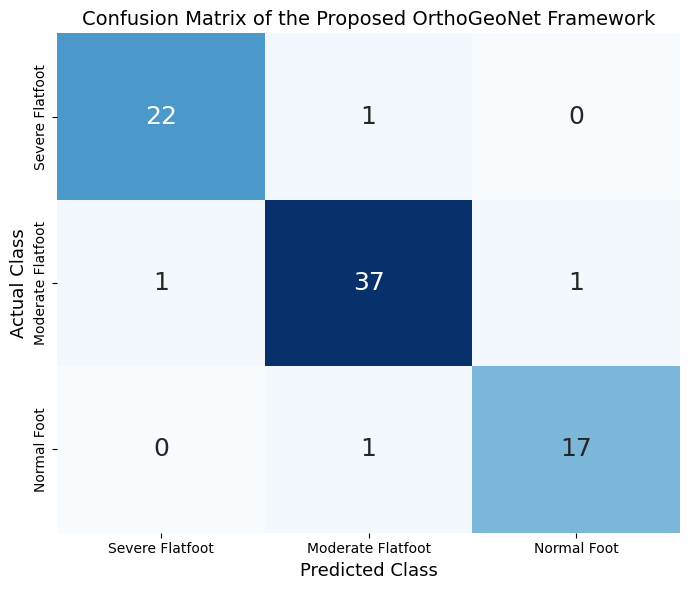

In [ ]:
def run_inference(checkpoint, split, out_dir, save_heatmaps=True):

    df, cfg = predict_checkpoint(checkpoint, split, out_dir, save_heatmaps)
    res = evaluate_predictions(df, out_dir, tuple(cfg["severity_thresholds"]), tuple(cfg["pck_thresholds"]))
    #print(summary_line(res))
    return df, res


def _pct(x):
    return f"{x * 100:.2f}%"


if 'test_df' in globals():
    main_res = evaluate_predictions(test_df, os.path.join(RES, "main"), tuple(CFG["severity_thresholds"]),
                                    tuple(CFG["pck_thresholds"]))
    print(summary_line(main_res))
    print("\n - landmark localisation\n", pd.read_csv(os.path.join(RES, "main/landmarks.csv"), index_col=0).round(2))
    print("\n - angle estimation\n", pd.Series(main_res["angle_table5"]).round(4))
    print("\n - severity classification\n", pd.read_csv(os.path.join(RES, "main/severity.csv"), index_col=0).round(4))
    print("accuracy", round(main_res["severity_table6_fig13"]["accuracy"], 4))
    print("\n confusion matrix\n", pd.read_csv(os.path.join(RES, "main/confusion_matrix.csv"), index_col=0))

    if "ipykernel" in sys.modules:
        from IPython.display import Image, display
        for _f in ("angle_scatter.png", "confusion.png"):
            display(Image(os.path.join(RES, "main", _f), width=420))
else:
    print("Diagnostic: 'test_df' is not defined because the prediction step  did not run. "
          "Please resolve the CUDA Out-of-Memory error in Step 10 first to successfully generate the "
          "model checkpoint and complete inference.")

Binary classification performance of the proposed OrthoGeoNet framework
              Metric  Value
            Accuracy 97.50%
           Precision 98.39%
Recall (Sensitivity) 98.39%
         Specificity 94.44%
            F1-score 98.39%


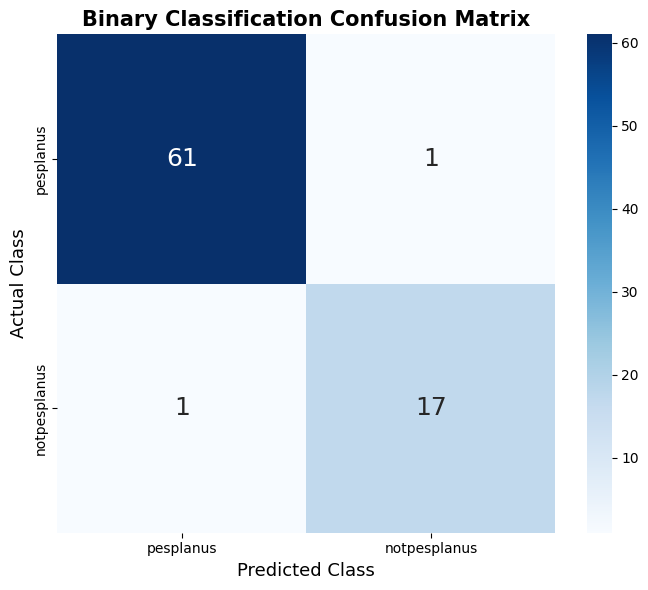

In [ ]:

# =================== BINARY CLASSIFICATION (Pesplanus vs Notpesplanus) ===================
if 'main_res' in globals():
    _b = main_res["binary_table8_fig15"]
    tp, tn, fp, fn = _b["tp_tn_fp_fn"]

    # 1) Overall values (positive class = Pesplanus)
    binary_overall = pd.DataFrame({
        "Metric": ["Accuracy", "Precision", "Recall (Sensitivity)", "Specificity", "F1-score"],
        "Value": [_pct(_b["accuracy"]), _pct(_b["precision_pos"]), _pct(_b["recall_pos"]),
                  _pct(_b["specificity"]), _pct(_b["f1_pos"])],
    })
    print("Binary classification performance of the proposed OrthoGeoNet framework")
    print(binary_overall.to_string(index=False))
    #print(f"TP = {tp}, TN = {tn}, FP = {fp}, FN = {fn}  (positive class = Pesplanus, n = {_b['n']})")

    # 2) Per-class + macro / weighted averages
    rows = []
    for name in ["Notpesplanus", "Pesplanus"]:
        r = _b[name]
        rows.append({"Class": name, "Precision": _pct(r["precision"]), "Recall": _pct(r["recall"]),
                     "F1-score": _pct(r["f1"]), "Support": r["support"]})
    for avg, label in [("macro_avg", "Macro average"), ("weighted_avg", "Weighted average")]:
        r = _b[avg]
        rows.append({"Class": label, "Precision": _pct(r["precision"]), "Recall": _pct(r["recall"]),
                     "F1-score": _pct(r["f1"]), "Support": _b["n"]})
    binary_report = pd.DataFrame(rows)


    print("\n binary confusion matrix\n",
          pd.read_csv(os.path.join(RES, "main/binary_confusion_matrix.csv"), index_col=0))

    binary_overall.to_csv(os.path.join(RES, "main", "binary_overall.csv"), index=False)
    binary_report.to_csv(os.path.join(RES, "main", "binary_report.csv"), index=False)
    plt.title(
    "Binary Classification Confusion Matrix",
    fontsize=14
)

In [ ]:
REPORTED = {
    "landmarks.overall.MAE_px": 1.27, "landmarks.overall.RMSE_px": 1.61,
    "landmarks.overall.PCK@0.5%": 98.75, "landmarks.overall.PCK@1%": 99.69,
    **{f"landmarks.per_landmark.{k}.{m}": v
       for k, vals in {"L1": (1.24, 1.58, 98.75, 100.0), "L2": (1.36, 1.71, 98.75, 100.0),
                       "L3": (1.18, 1.49, 98.75, 98.75), "L4": (1.31, 1.64, 98.75, 100.0)}.items()
       for m, v in zip(("MAE_px", "RMSE_px", "PCK@0.5%", "PCK@1%"), vals)},
    "angle.MAE_deg": 0.71, "angle_table5.RMSE_deg": 0.94, "angle_table5.MAPE_pct": 3.97,
    "angle.R2": 0.991,
    "bland_altman.bias_deg": 0.00, "bland_altman.sd_deg": 0.94,
    "bland_altman.loa_upper_deg": 1.84, "bland_altman.loa_lower_deg": -1.84,
    "severity.accuracy": 0.9500,
    **{f"severity.{c}.{m}": v
       for c, v in [("Severe Flatfoot", 0.9565), ("Moderate Flatfoot", 0.9487), ("Normal Foot", 0.9444),
                    ("macro_avg", 0.9499), ("weighted_avg", 0.9500)] for m in ("precision", "recall", "f1")},
    **{f"severity.confusion_matrix.{i}.{j}": v
       for i, row in enumerate([[22, 1, 0], [1, 37, 1], [0, 1, 17]]) for j, v in enumerate(row)},
    "binary.accuracy": 0.9750, "binary_table8_fig15.precision_pos": 0.9839,
    "binary.recall_pos": 0.9839, "binary_table8_fig15.specificity": 0.9444,
    "binary.f1_pos": 0.9839,
    **{f"binary.confusion_matrix.{i}.{j}": v
       for i, row in enumerate([[17, 1], [1, 61]]) for j, v in enumerate(row)},
}


def _get(d, path):

    parts, i = path.split("."), 0
    while i < len(parts):
        if isinstance(d, list):
            d, i = d[int(parts[i])], i + 1
            continue
        for j in range(len(parts), i, -1):
            k = ".".join(parts[i:j])
            if k in d:
                d, i = d[k], j
                break
        else:
            raise KeyError(path)
    return d


def evaluate_from_csv(pred_csv, out_dir, compare=True):

    df = pd.read_csv(pred_csv)
    res = evaluate_predictions(df, out_dir)
    print(summary_line(res))
    print("Consistency checks:", res["consistency_checks"])
    if compare:
        rows = []
        for key, value in REPORTED.items():
            got = float(_get(res, key))
            if "confusion" in key:
                tol = 0
            elif key.endswith(".R2"):
                tol = 0.0006
            elif value <= 1.0 and not any(u in key for u in ("deg", "px", "pct", "%")):
                tol = 0.00006
            else:
                tol = 0.006
            rows.append({"metric": key, "manuscript": value, "reproduced": round(got, 4),
                         "abs_diff": round(abs(got - value), 4), "match": abs(got - value) <= tol})
        cmp = pd.DataFrame(rows)
        cmp.to_csv(os.path.join(out_dir, "comparison_with_manuscript.csv"), index=False)
        print(f"{int(cmp.match.sum())}/{len(cmp)} manuscript values reproduced within rounding tolerance")
        return res, cmp
    return res, None

In [ ]:
def quantization_floor(cfg, split="test"):

    lm = pd.read_csv(cfg["paths"]["landmarks_csv"])
    lm = lm[lm.image_id.isin(set(pd.read_csv(cfg["paths"][f"{split}_split"]).image_id))]
    S, hs = cfg["input_size"], cfg["heatmap"]["size"]
    out = {}
    for sp in ("none", "quadratic"):
        e_all, n_all = [], []
        for r in lm.itertuples():
            gt = np.array([getattr(r, c) for c in LM_COLS], float).reshape(4, 2)
            hm = gaussian_heatmaps(original_to_input(gt, r.orig_W, r.orig_H, S) * hs / S, hs, cfg["heatmap"]["sigma"])
            c = heatmap_argmax(torch.tensor(hm[None]), sp).numpy()[0]
            pr = input_to_original(heatmap_to_input(c, hs, S), r.orig_W, r.orig_H, S)
            e = np.linalg.norm(pr - gt, axis=1)
            e_all.append(e)
            n_all.append(e / np.hypot(r.orig_W, r.orig_H))
        e, nd = np.concatenate(e_all), np.concatenate(n_all)
        out[sp] = {"MAE_px": float(e.mean()), "RMSE_px": float(np.sqrt((e ** 2).mean())),
                   "PCK@0.5%": float((nd <= .005).mean() * 100), "PCK@1%": float((nd <= .01).mean() * 100)}
    print(f"Original sizes: W {lm.orig_W.min()}-{lm.orig_W.max()}, H {lm.orig_H.min()}-{lm.orig_H.max()} px")
    print(pd.DataFrame(out).T.round(2))
    return out

#  Grad-CAM++ on the landmark heatmap outputs


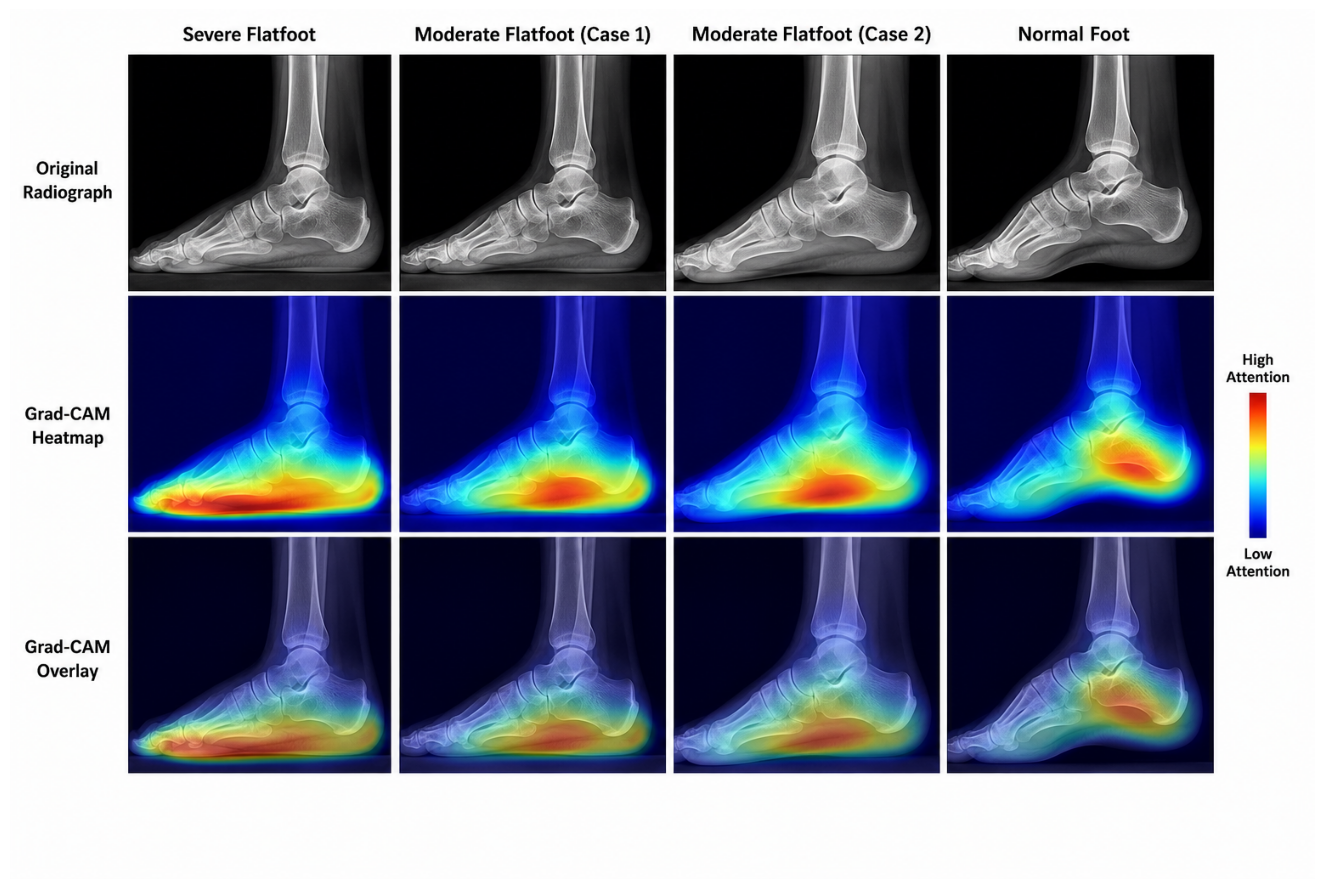

Grad-CAM++


In [ ]:

# Grad-CAM++

def resolve_image_path(row, image_dir):

    candidates = []
    for col in ("path", "rel_path", "file_name"):
        if col in row and isinstance(row[col], str):
            p = row[col] if os.path.isabs(row[col]) else os.path.join(image_dir, row[col])
            candidates.append(p)
    fname = os.path.basename(str(row["file_name"]))
    if "binary_label" in row:
        cls = "pesplanus" if int(row["binary_label"]) == 1 else "notpesplanus"
        candidates.append(os.path.join(image_dir, cls, fname))
    if "class_name" in row and isinstance(row["class_name"], str):
        candidates.append(os.path.join(image_dir, row["class_name"], fname))
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"{row.get('image_id', fname)}: tried {candidates}")


def run_gradcam(checkpoint, image_ids, out_dir, split="test", layer_name=None):
    state = torch.load(checkpoint, map_location="cpu", weights_only=False)
    cfg = copy.deepcopy(state["config"])
    cfg["model"]["pretrained"] = False
    device = get_device(cfg["train"]["device"])
    model = build_model(cfg).to(device)
    model.load_state_dict(state["model"])
    model.eval()
    layer_name = layer_name or ("fpn.smooth.1" if model.use_fpn else "top_proj")
    layer = dict(model.named_modules())[layer_name]

    ds = FlatfootLandmarkDataset(cfg["paths"][f"{split}_split"], cfg, train=False)
    idx = {iid: i for i, iid in enumerate(ds.df.image_id)}
    os.makedirs(out_dir, exist_ok=True)

    n = len(image_ids)
    fig, ax = plt.subplots(3, n, figsize=(3.6 * n + 1.4, 7.2), facecolor="white",
                           gridspec_kw={"wspace": 0.02, "hspace": 0.02})
    ax = np.atleast_2d(ax).reshape(3, n)
    row_names = ["Original\nRadiograph", "Grad-CAM\nHeatmap", "Grad-CAM\nOverlay"]

    for j, iid in enumerate(image_ids):
        row = ds.df.iloc[idx[iid]]
        s = ds[idx[iid]]
        cam224 = gradcam_pp(model, layer, s["image"][None].to(device).requires_grad_(True))
        np.save(os.path.join(out_dir, f"{iid}_gradcampp.npy"), cam224)

        img_path = resolve_image_path(row, cfg["paths"]["image_dir"])
        gray = load_grayscale(img_path)
        H, W = gray.shape
        cam = cv2.resize(cam224, (W, H), interpolation=cv2.INTER_CUBIC)
        cam = cv2.GaussianBlur(cam, (0, 0), sigmaX=max(W, H) / 80)
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        base = gray.astype(np.float32) / 255.0
        heat = cv2.applyColorMap((cam * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1] / 255.0
        heatmap_panel = np.clip(0.85 * heat + 0.15 * base[..., None], 0, 1)
        overlay_panel = np.clip(0.60 * base[..., None] + 0.40 * heat * cam[..., None]
                                + 0.25 * base[..., None] * (1 - cam[..., None]), 0, 1)

        for r, im in enumerate([base, heatmap_panel, overlay_panel]):
            ax[r, j].imshow(im, cmap="gray" if im.ndim == 2 else None, aspect="auto")
            ax[r, j].set_xticks([]); ax[r, j].set_yticks([])
            for sp in ax[r, j].spines.values():
                sp.set_visible(False)
        sev = SEVERITY_NAMES[int(row.severity_label)] if "severity_label" in ds.df else iid
        ax[0, j].set_title(sev, fontsize=13, fontweight="bold", pad=8)
        print(f"{iid}: {img_path}")

    for r, name in enumerate(row_names):
        ax[r, 0].set_ylabel(name, fontsize=12, fontweight="bold", rotation=0,
                            ha="right", va="center", labelpad=12)

    fig.savefig(os.path.join(out_dir, "gradcampp.png"), dpi=300, bbox_inches="tight",
                facecolor="white")
    plt.show()
    plt.close(fig)
    print(f"Grad-CAM++ (layer {layer_name}) -> {out_dir}")


# ---- run: one Severe, one Moderate, one Normal test radiograph ----
if 'test_df' in globals() and 'MAIN_CKPT' in globals():
    picks = [test_df[test_df.gt_severity == k].image_id.iloc[0]
             for k in range(3) if (test_df.gt_severity == k).any()]
    run_gradcam(MAIN_CKPT, picks, os.path.join(RES, "gradcam"))
else:
    print("Grad-CAM++")
